# Committor Model: 2D Brownian Z Potential, Staple Paths, Longer Fit

Continues the NPNEq fit of the staple run `sim_istarz_br_g10` (overdamped Langevin, γ = 10, kT = 0.05, dt = 0.002, Z potential `sjoelbak_angle(Lx=0.3, angle=45)`), with the same data and settings as the original fit by `load_tis_data_cupy.py`, only for longer. Optionally adds the ridge-normal coordinate y + x as a CV.

**Why:** the original fit (10000 iterations) put the plateau beyond the 45° ridge 0.05–0.07 too high, confirmed by shooting with the toytis engine (`docs/npneq_tis_notes.md`, `figures_by_potential/2d_zpot/brownian_g10/reference_and_analyses/`). Its `zqs_z` was still falling (3.68 → 3.23 over the last 6000 iterations) and the stopped Z_q sat at about −3 at the longest lags for q below the plateau. Two questions: does it converge with more iterations, and does a CV aligned with the ridge (y + x) remove the overshoot?

**Data:** the original fit's `figures_by_potential/2d_zpot/brownian_g10/staple/original/committor.npz`: 29975 accepted paths (3000 per ensemble), each cut at its first frame past M, 20.8M frames, MC path weights (`rejections`), and the fitted q. It can also be re-read from the run with `tis_data.prepare_data` (section 2).

**Boundaries:** `y <= 0.05` (A) and `y >= 0.85` (B), the first and last interfaces. The order parameter y is the first position of the phase point; x is the transverse position.

## 1. Imports

In [20]:
import argparse
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
import cupy as cp
from scipy.interpolate import RegularGridInterpolator

# Plot styling
plt.rc('font', size=10)
plt.rc('axes', titlesize=14)
plt.rc('axes', labelsize=14)
plt.rc('xtick', labelsize=12)
plt.rc('ytick', labelsize=12)
plt.rc('legend', fontsize=12)

# Custom optimal-RC / committor package (CuPy) and the path-data loader of the examples
REPO = '/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs'
sys.path.insert(0, f'{REPO}/optimalrcs-cupy/')
sys.path.insert(0, f'{REPO}/examples/')
import optimalrcs, metrics, plots
import tis_data
FIG = f'{REPO}/examples/figures_by_potential'

## 2. Data Loading

By default the frames and the fitted q of the original fit are loaded from `committor.npz` (3000 accepted paths per ensemble, rejection weights, cut at M, no mirrored pieces), so the data and their order are exactly those of that fit.

**Other paths:** with `REREAD = True` the paths are read again from `TIS_DIR` with `tis_data.prepare_data`, and a different set can be chosen:

| Option | Meaning |
|---|---|
| `PATHS_PER_ENSEMBLE` | random subset of accepted paths per ensemble, weights kept (`None` = all paths in `TIS_DIR`) |
| `PATH_SEED` | which random subset: different seeds give different paths |
| `REVERSED` | add the mirrored pieces (the part before the last M crossing, read backwards) |
| `WEIGHTS` | MC path weights (`rejections`, `staple` or `none`) |

`TIS_DIR` decides what can be drawn from. A folder with the full run (all ~50000 accepted paths per ensemble) gives independent 3000-path sets for different `PATH_SEED`s. A folder that holds only the 3000-path subset (the copy used for the original fit) allows smaller subsets of those paths only (e.g. `PATHS_PER_ENSEMBLE = 1500` with different seeds). The figures and the saved fit carry `DATA_TAG` (e.g. `p3000_s1`, `all_rev`, `orig`) in their names, so runs on different paths do not overwrite each other. With `CONTINUE = True` the saved q is used only if it belongs to the same frames; otherwise the fit starts from scratch.

The independence group of a frame (`group_traj`) is its path: with `REVERSED` the forward and mirrored piece of a path form one group.

In [21]:
FIT_NPZ = f'{FIG}/2d_zpot/brownian_g10/reference_and_analyses/committor_long.npz'
REREAD = True                     # False: the original fit's frames and q from FIT_NPZ; True: read paths from TIS_DIR
TIS_DIR = '/home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istarz_br_g10'
PATHS_PER_ENSEMBLE = 2500          # REREAD only: random subset of accepted paths per ensemble (None = all in TIS_DIR)
PATH_SEED = 1521242                      # REREAD only: which random subset
REVERSED = True                   # REREAD only: add the mirrored pieces
WEIGHTS = 'rejections'             # REREAD only: MC path weights

if REREAD:
    parser = argparse.ArgumentParser()
    tis_data.add_data_arguments(parser)
    argv = [TIS_DIR, '--weights', WEIGHTS]
    if PATHS_PER_ENSEMBLE is not None:
        argv += ['--paths-per-ensemble', str(PATHS_PER_ENSEMBLE), '--seed', str(PATH_SEED)]
    if REVERSED:
        argv += ['--reversed']
    data = tis_data.prepare_data(parser.parse_args(argv))
    X_all, lam, i_traj, t_traj = data.X_all, data.lam, data.i_traj, data.t_traj
    path_weights, boundary0, boundary1 = data.path_weights, data.boundary0, data.boundary1
    group_traj = data.group_traj                   # forward and mirrored piece of a path: one group
    DATA_TAG = (f'p{PATHS_PER_ENSEMBLE}_s{PATH_SEED}' if PATHS_PER_ENSEMBLE is not None else 'all') \
               + ('_rev' if REVERSED else '') + ('' if WEIGHTS == 'rejections' else f'_{WEIGHTS}')
    r_saved = np.load(FIT_NPZ)['r'] if os.path.exists(FIT_NPZ) else None
    if r_saved is not None and len(r_saved) != len(lam):
        r_saved = None                             # a different data set: start from scratch
else:
    d = np.load(FIT_NPZ)
    X_all, lam, i_traj, t_traj = d['X_all'], d['lam'], d['i_traj'], d['t_traj']
    path_weights, boundary0, boundary1 = d['path_weights'], d['boundary0'], d['boundary1']
    r_saved = d['r']
    group_traj = i_traj                            # one segment per path (no mirrored pieces)
    DATA_TAG = 'orig'
y_pos, x_pos = X_all[:, 0], X_all[:, 1]
lambda_a, lambda_b = 0.05, 0.85
print(f'data {DATA_TAG}: {len(lam)} frames in {len(np.unique(i_traj))} pieces from {len(np.unique(group_traj))} paths; '
      f'frames in A {boundary0.sum()}, in B {boundary1.sum()}')

Interfaces from /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istarz_br_g10/logging.log: [0.05, 0.13, 0.21, 0.29, 0.37, 0.45, 0.53, 0.61, 0.69, 0.77, 0.85]
State A: order <= 0.05, state B: order >= 0.85
Note: --seed is ignored; paths are thinned in a fixed pattern (--thin, --paths-per-ensemble), not drawn at random
Found 11 ensemble folders in /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istarz_br_g10
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istarz_br_g10/001: loaded 3523 pieces, 48407 frames, total weight 9530, cut at M = 0.05 (1 paths dropped: core never crosses M)
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istarz_br_g10/002: loaded 3598 pieces, 1671588 frames, total weight 7828, cut at M = 0.13
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istarz_br_g10/003: loaded 3604 pieces, 2349812 frames, total weight 7152, cut at M = 0.21
  /home/staff7/fbsskr/Notebooks/Students/e

## 3. Train Committor (Non-Parametric), Continued

Same settings as the original fit (`load_tis_data_cupy.py` defaults with `--lazy-basis`). The original run set no random seeds, so the CV draws differ; a seed is set here for reproducibility.

With `CONTINUE = True` the fit starts from the saved q (10000 iterations done), otherwise from scratch. With `ADD_DIAG = True` the CVs are (y, x, y + x): y + x is the coordinate normal to the ridge, so a single update can follow the 45° step.

Paths stop at their first A/B frame; `set_fixed_traj_length_trap` treats those ends as traps so the Z_q-based metrics keep the windows that run into A or B. Convergence: `zqs_z` (worst |stopped Z_q / standard error| over q and lags) about 2 or less; for paths cut at t\* the stopped Z_q of the committor is 0 (notes §8.1).

**Parameters:**
| Parameter | Value | Description |
|-----------|-------|-------------|
| `envelope_scale` | 0.01 | RC envelope width (library default, as in the original fit) |
| `gamma` | 0.1 | Regularization (scales the step; does not change the fixed point) |
| `ny` | 6 | Polynomial degree |
| `max_iter` | 30000 | Iterations in this run (~0.4 s each on 20.8M frames) |
| `lazy_basis` | True | Basis in fused GPU kernels (less memory, same result) |
| `CONTINUE` | True | Start from the saved q |
| `ADD_DIAG` | False | Add y + x as a CV |

**Seeds and warm-up** (`seed_runs.run_seeds`, shared with the other notebooks): the fit is repeated for every seed in `SEEDS` (the seed sets which CV and envelope centre each iteration draws). The first `WARMUP_ITER` iterations of every seed can use their own envelope (`WARMUP_ENVELOPE`), gamma (`WARMUP_GAMMA`) and CV (`WARMUP_CV`: `None` random, otherwise the index of the CV to use); then `ENVELOPE` and `GAMMA` take over (`WARMUP_ITER = 0`: no warm-up). After the warm-up and every `CHUNK` iterations the plots in `PLOTS` are shown here and saved to `<OUT>/seed<s>/it<N>_<plot>.png`, with a progress line. The objects of earlier seeds are freed; `q` is the last seed's fit and `results[seed]['r']` every seed's RC.

**Committor map per chunk** (`seed_runs.committor_map`): after the warm-up and every chunk, the mean q per (y, x) bin next to the exact committor and fit − exact (with its RMS over the bins where 0.05 < q_exact < 0.95), on the effective potential, as in section 4; saved as `it<N>_q_y_x.png`.

#=500, dr2=242.394, zqs_z=5.457, sdzqs=6.95812, |dx|=0.38264, time=45.0469
#=1000, dr2=238.707, zqs_z=5.05759, sdzqs=6.61022, |dx|=0.00180364, time=89.8258
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/nb_brownian_staple/yx/seed45/it1000 ---


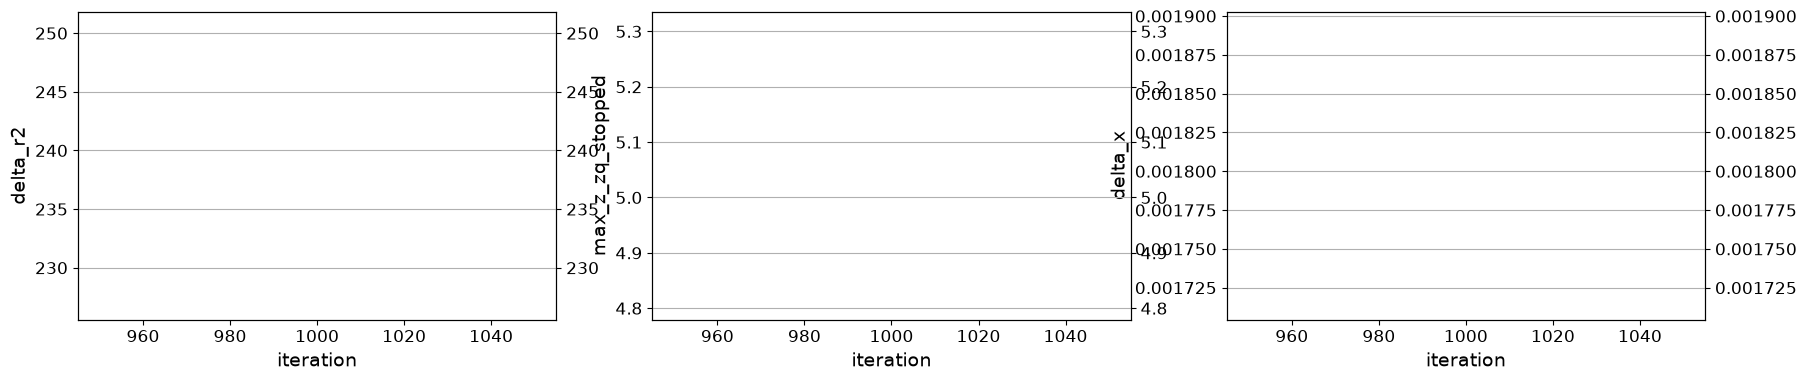

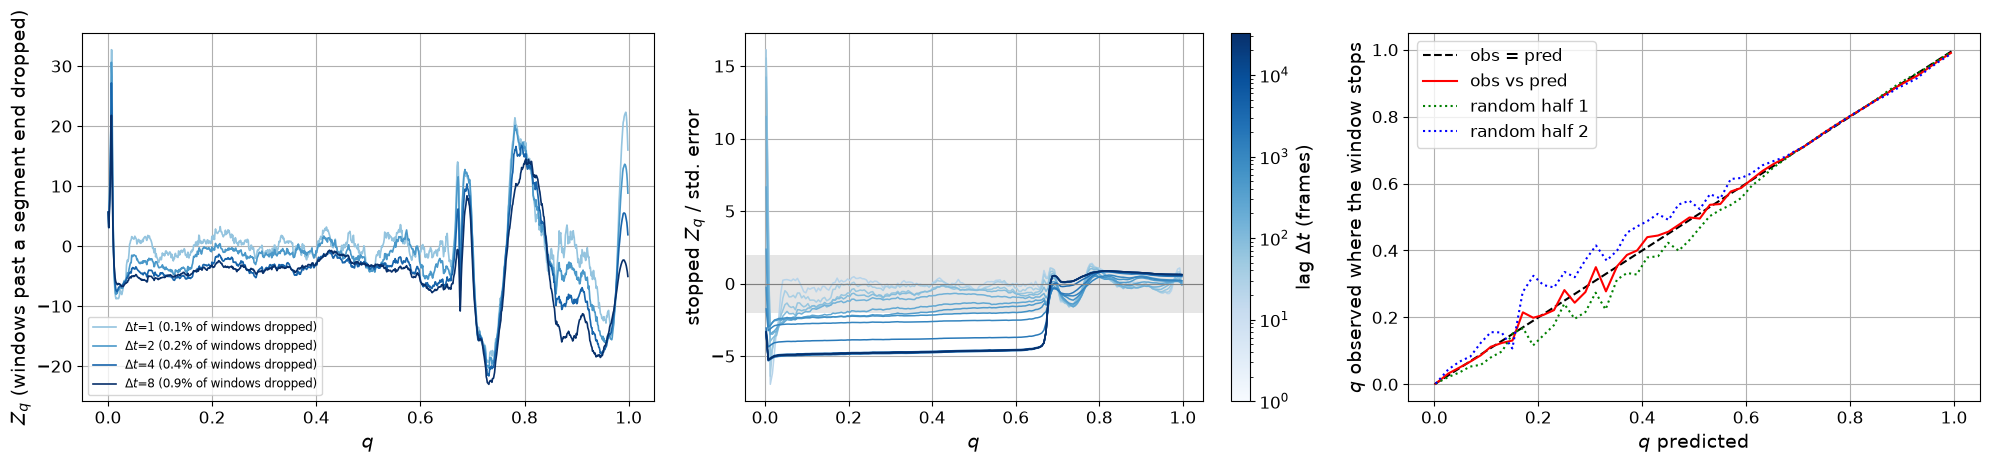

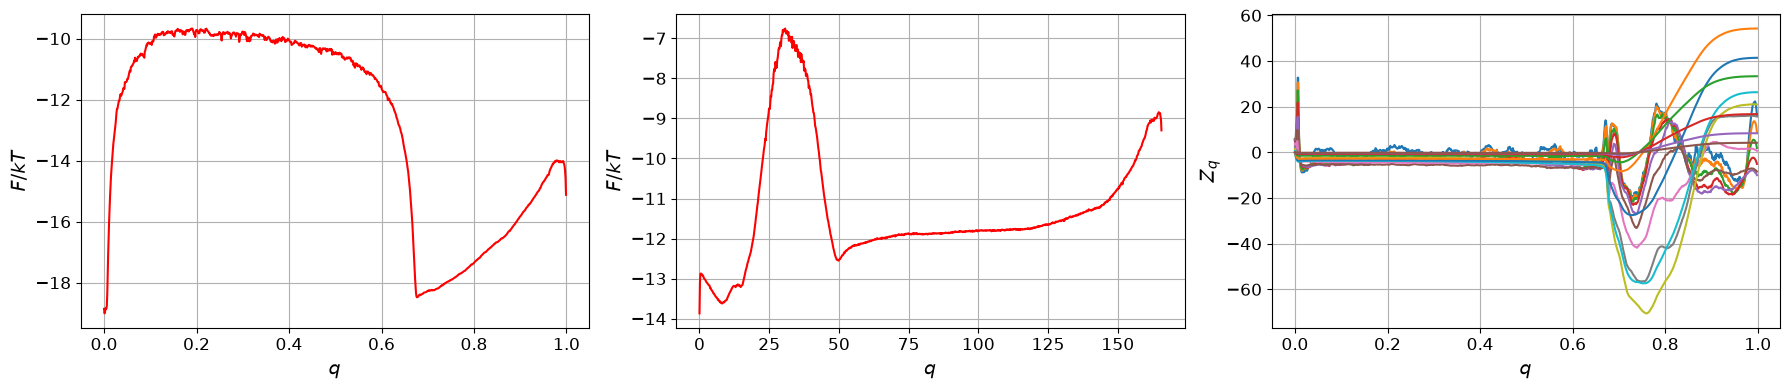

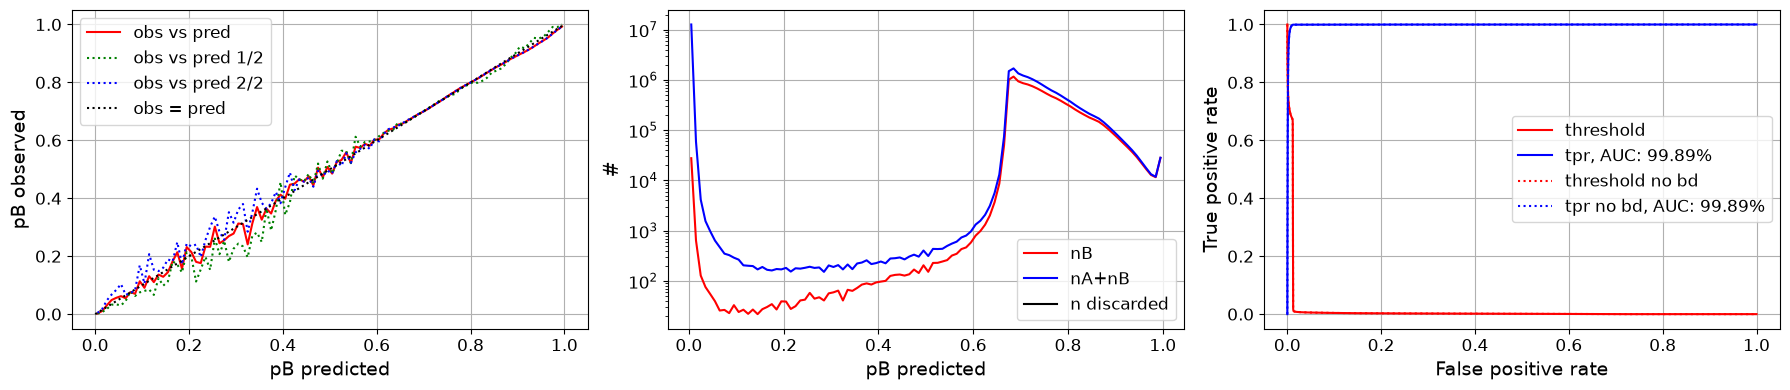

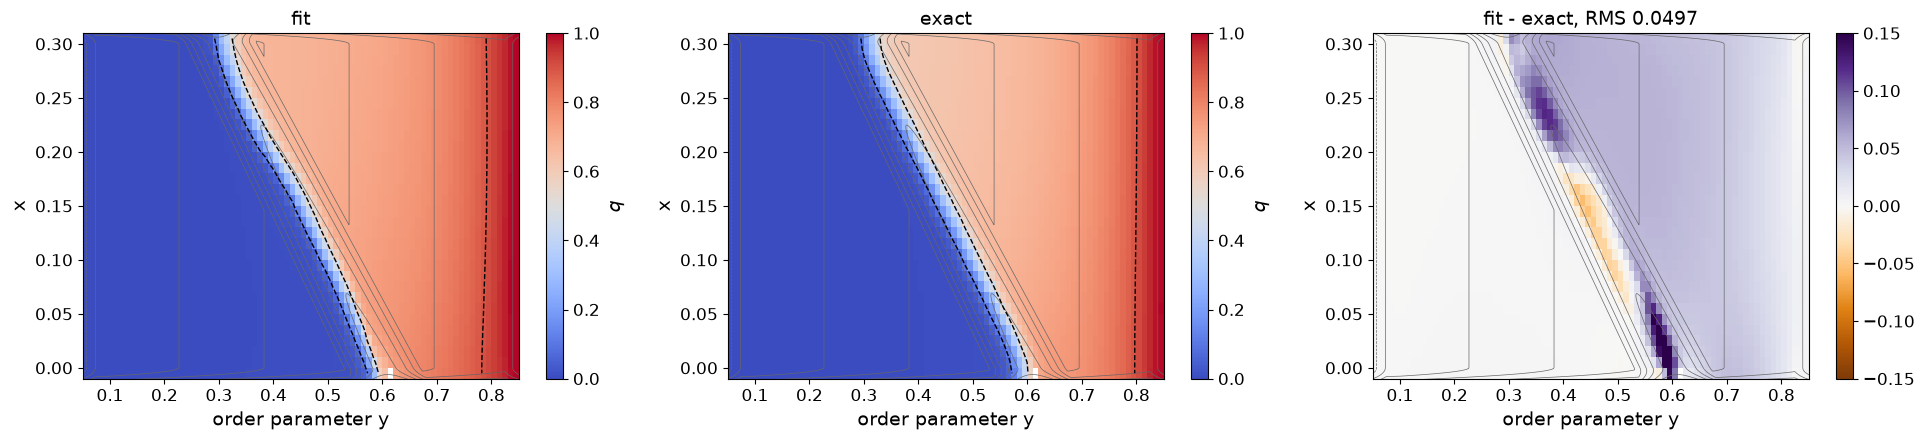

seed 45, 1000 iterations (warm-up: envelope 1000000, gamma 0.0) | fit/shooting at plateau points: 0.693/0.639 0.724/0.664 0.742/0.698 0.789/0.747
#=1500, dr2=230.46, zqs_z=3.94456, sdzqs=4.36878, |dx|=0.00291563, time=44.6919
#=2000, dr2=229.102, zqs_z=3.78551, sdzqs=4.37919, |dx|=0.00081431, time=89.4739
#=2500, dr2=228.806, zqs_z=3.74777, sdzqs=4.41978, |dx|=0.000157175, time=134.242
#=3000, dr2=228.647, zqs_z=3.73458, sdzqs=4.34993, |dx|=0.000115797, time=179.006
#=3500, dr2=228.487, zqs_z=3.69848, sdzqs=4.33409, |dx|=6.93454e-05, time=223.759
#=4000, dr2=228.352, zqs_z=3.73372, sdzqs=4.30446, |dx|=8.90541e-05, time=268.515
#=4500, dr2=228.382, zqs_z=3.61738, sdzqs=4.31124, |dx|=7.99364e-05, time=313.277
#=5000, dr2=228.171, zqs_z=3.76787, sdzqs=4.26629, |dx|=0.000177034, time=358.057
#=5500, dr2=228.132, zqs_z=3.64628, sdzqs=4.21934, |dx|=5.55827e-05, time=402.832
#=6000, dr2=228.097, zqs_z=3.69224, sdzqs=4.22493, |dx|=4.85744e-05, time=447.61
--- /home/staff7/fbsskr/Notebooks/Stud

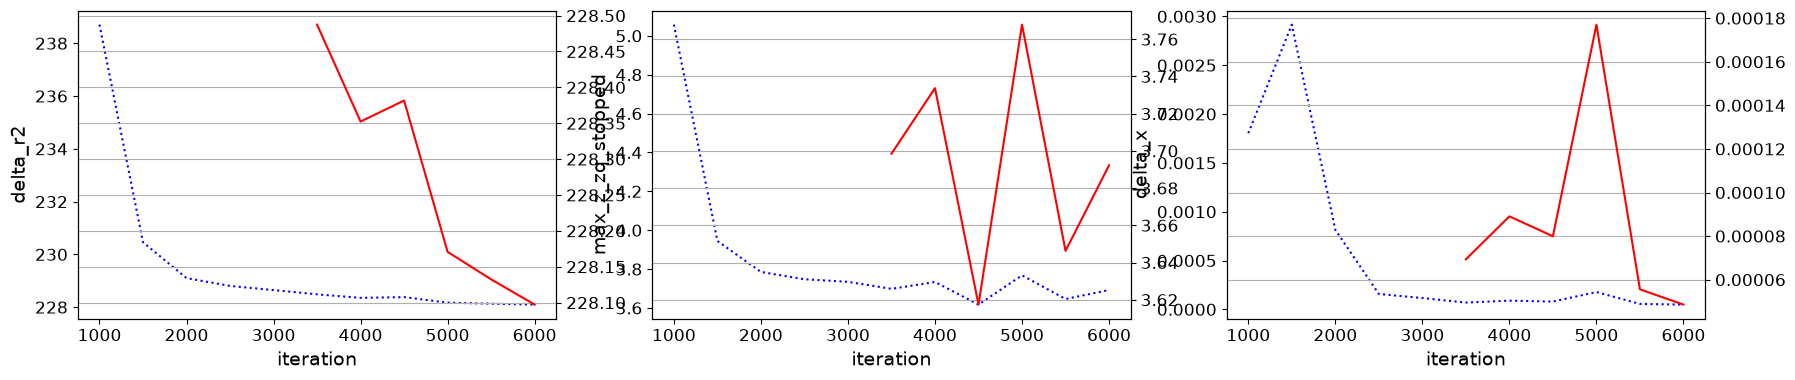

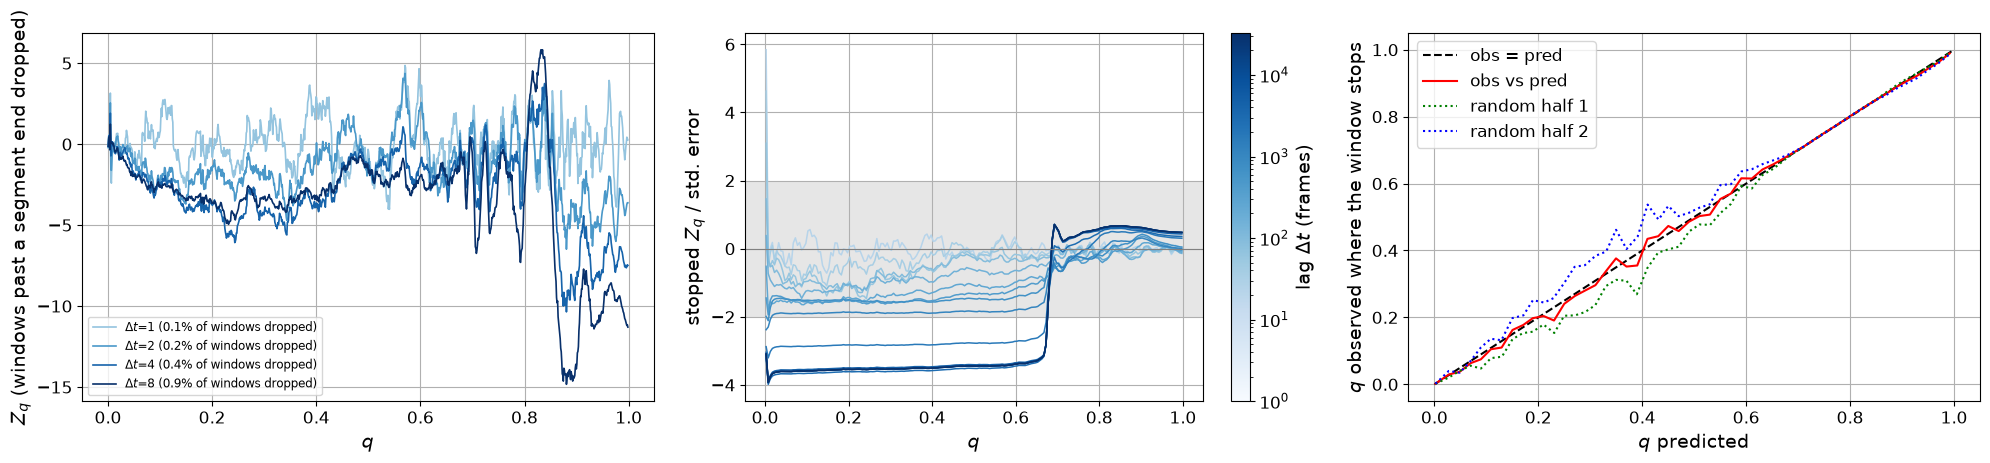

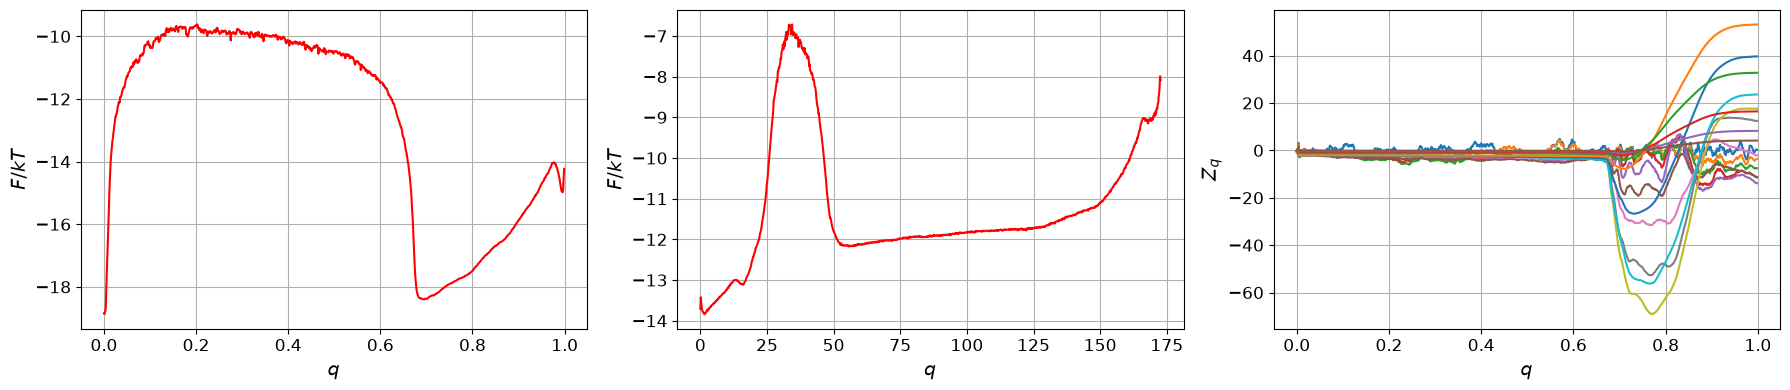

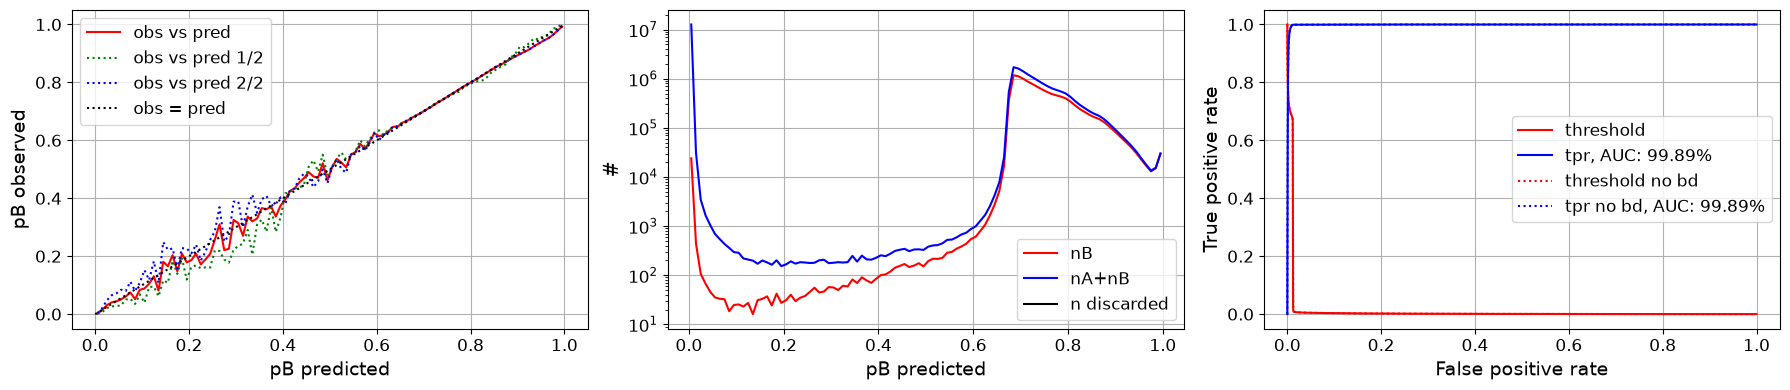

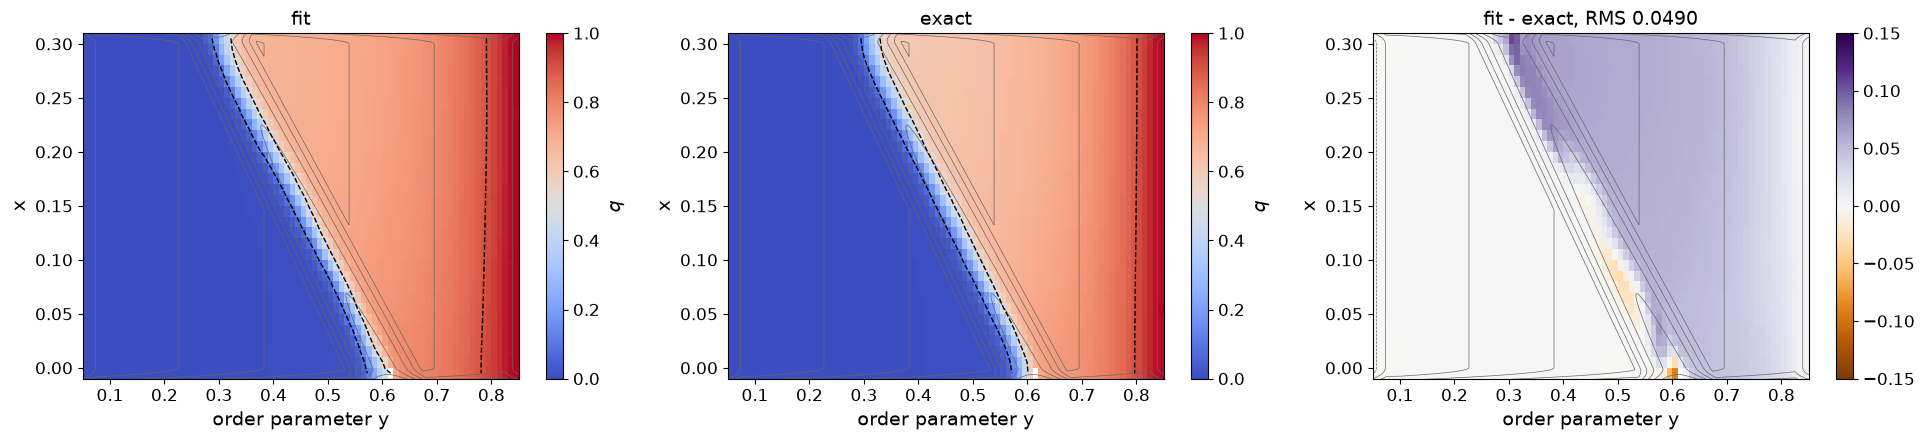

seed 45, 6000 iterations (main: envelope 0.01, gamma 0.0) | fit/shooting at plateau points: 0.699/0.639 0.728/0.664 0.747/0.698 0.794/0.747
#=6500, dr2=228.116, zqs_z=3.64561, sdzqs=4.22033, |dx|=5.54629e-05, time=44.6254
#=7000, dr2=228.073, zqs_z=3.63336, sdzqs=4.21271, |dx|=3.07834e-05, time=89.3876
#=7500, dr2=228.03, zqs_z=3.68691, sdzqs=4.19097, |dx|=6.00571e-05, time=134.149
#=8000, dr2=228.016, zqs_z=3.6357, sdzqs=4.18878, |dx|=3.23867e-05, time=178.92
#=8500, dr2=227.926, zqs_z=3.63271, sdzqs=4.15638, |dx|=6.89315e-05, time=223.682
#=9000, dr2=227.996, zqs_z=3.63243, sdzqs=4.17199, |dx|=8.03876e-05, time=268.463
#=9500, dr2=227.928, zqs_z=3.72305, sdzqs=4.15887, |dx|=5.34415e-05, time=313.229
#=10000, dr2=227.865, zqs_z=3.63853, sdzqs=4.13535, |dx|=5.15515e-05, time=358.008
#=10500, dr2=227.905, zqs_z=3.70779, sdzqs=4.13471, |dx|=5.85943e-05, time=402.785
#=11000, dr2=227.881, zqs_z=3.6356, sdzqs=4.14597, |dx|=3.29869e-05, time=447.6
--- /home/staff7/fbsskr/Notebooks/Students/

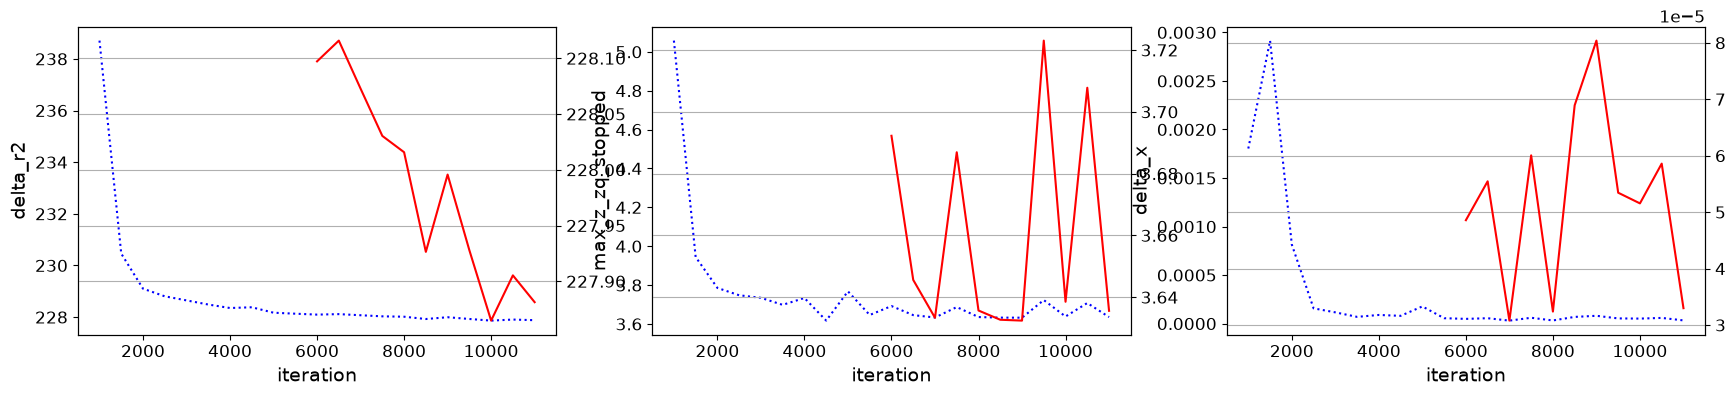

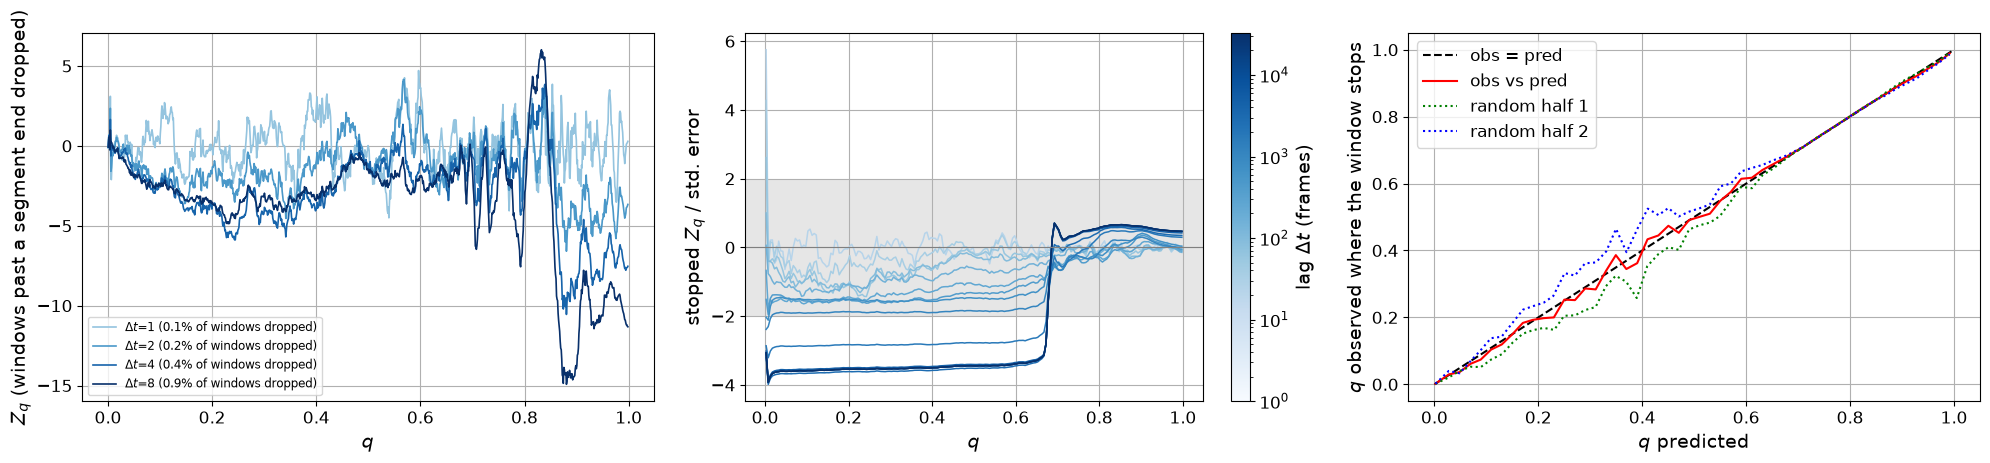

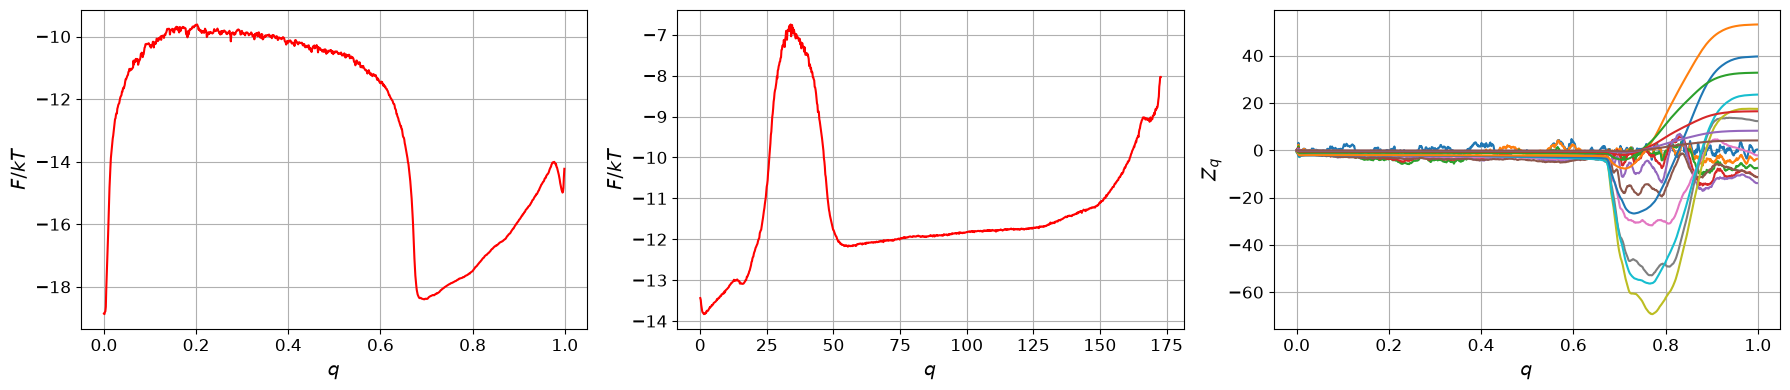

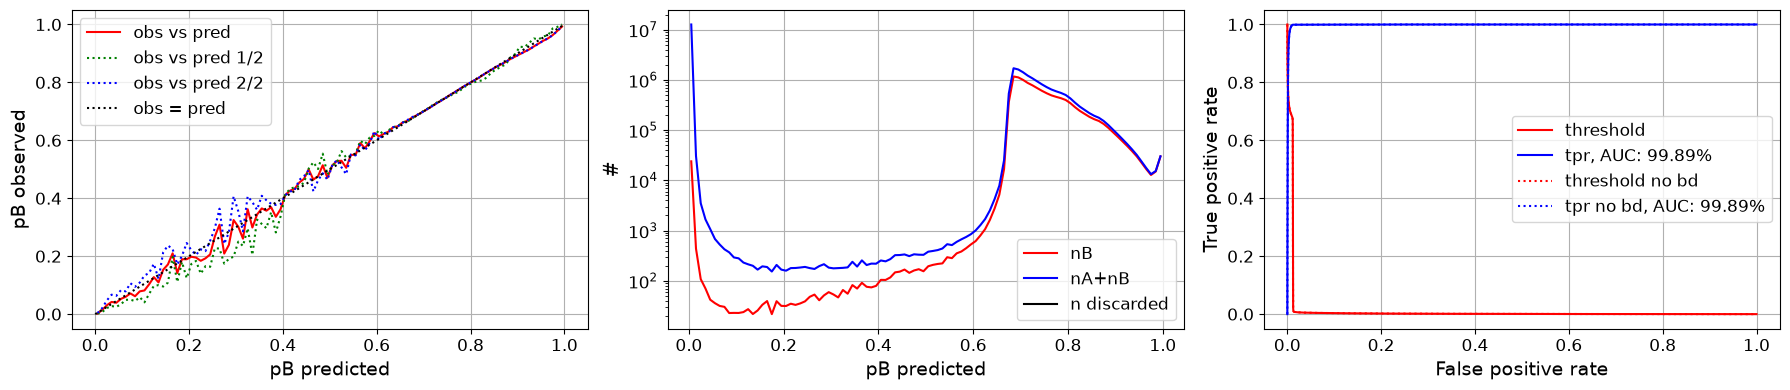

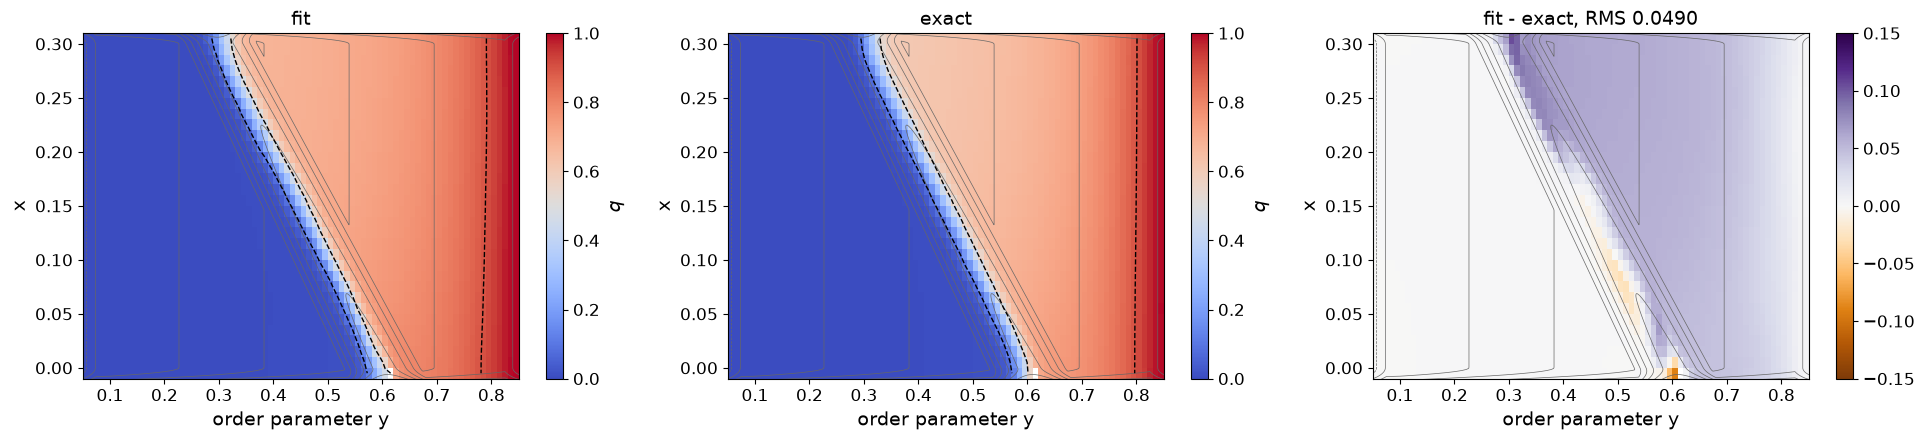

seed 45, 11000 iterations (main: envelope 0.01, gamma 0.0) | fit/shooting at plateau points: 0.699/0.639 0.728/0.664 0.747/0.698 0.794/0.747
#=11500, dr2=227.863, zqs_z=3.688, sdzqs=4.13955, |dx|=2.14454e-05, time=44.5516
#=12000, dr2=227.84, zqs_z=3.69315, sdzqs=4.14767, |dx|=2.9528e-05, time=89.3191
#=12500, dr2=227.82, zqs_z=3.72453, sdzqs=4.13735, |dx|=1.89479e-05, time=134.095
#=13000, dr2=227.827, zqs_z=3.68334, sdzqs=4.12229, |dx|=2.02919e-05, time=178.863
#=13500, dr2=227.791, zqs_z=3.64404, sdzqs=4.12539, |dx|=2.61092e-05, time=223.651
#=14000, dr2=227.782, zqs_z=3.70083, sdzqs=4.11875, |dx|=2.24944e-05, time=268.455
#=14500, dr2=227.727, zqs_z=3.76704, sdzqs=4.10523, |dx|=4.23164e-05, time=313.229
#=15000, dr2=227.744, zqs_z=3.65345, sdzqs=4.1209, |dx|=3.84729e-05, time=358.037
#=15500, dr2=227.707, zqs_z=3.66836, sdzqs=4.11087, |dx|=2.57593e-05, time=402.833
#=16000, dr2=227.676, zqs_z=3.70845, sdzqs=4.0959, |dx|=3.3824e-05, time=447.692
--- /home/staff7/fbsskr/Notebooks/Stu

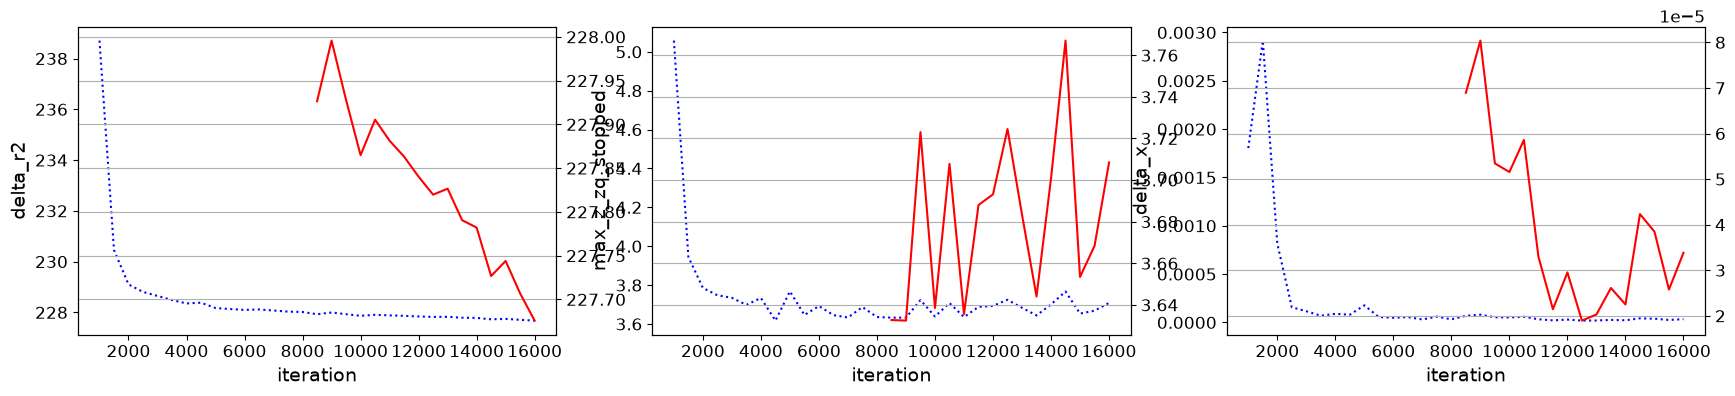

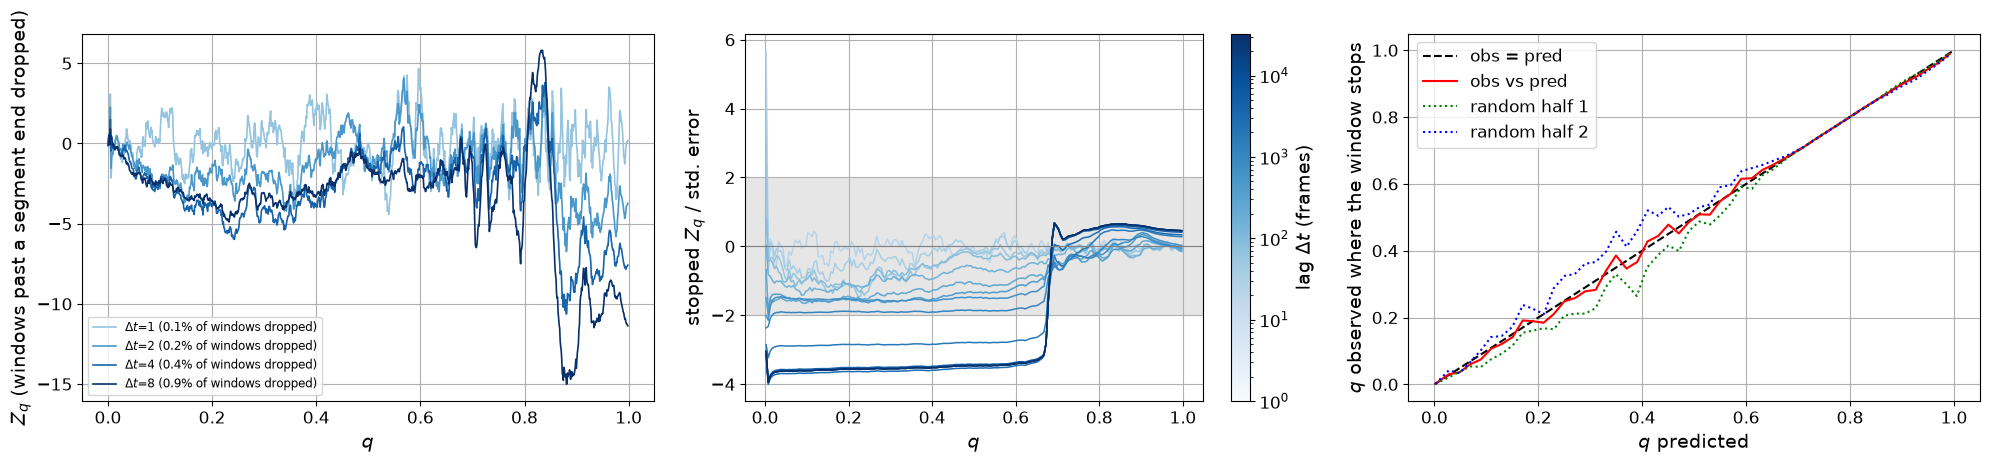

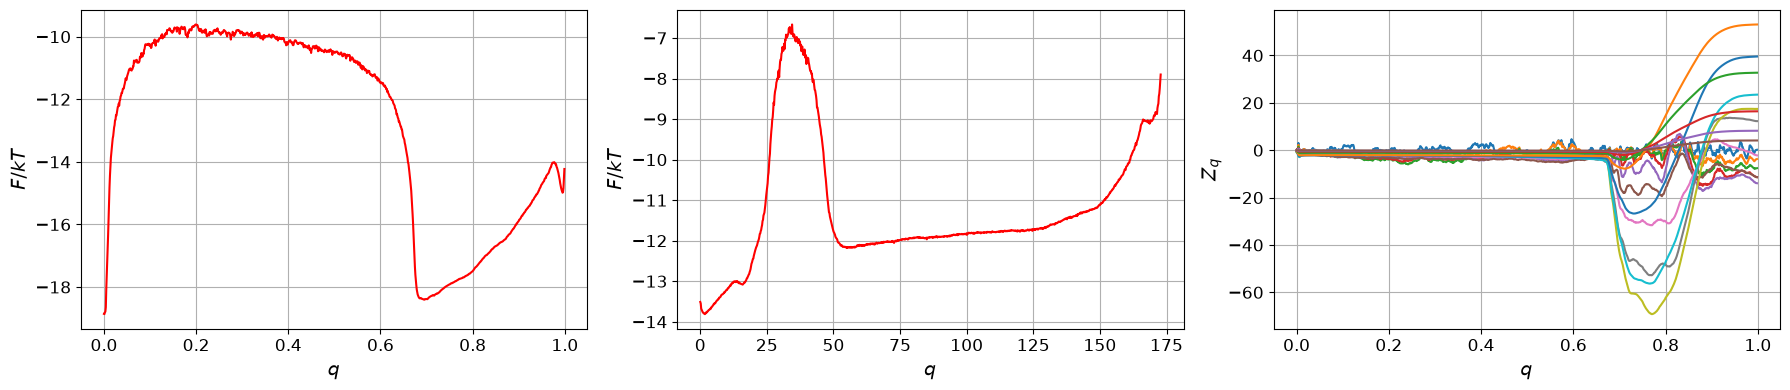

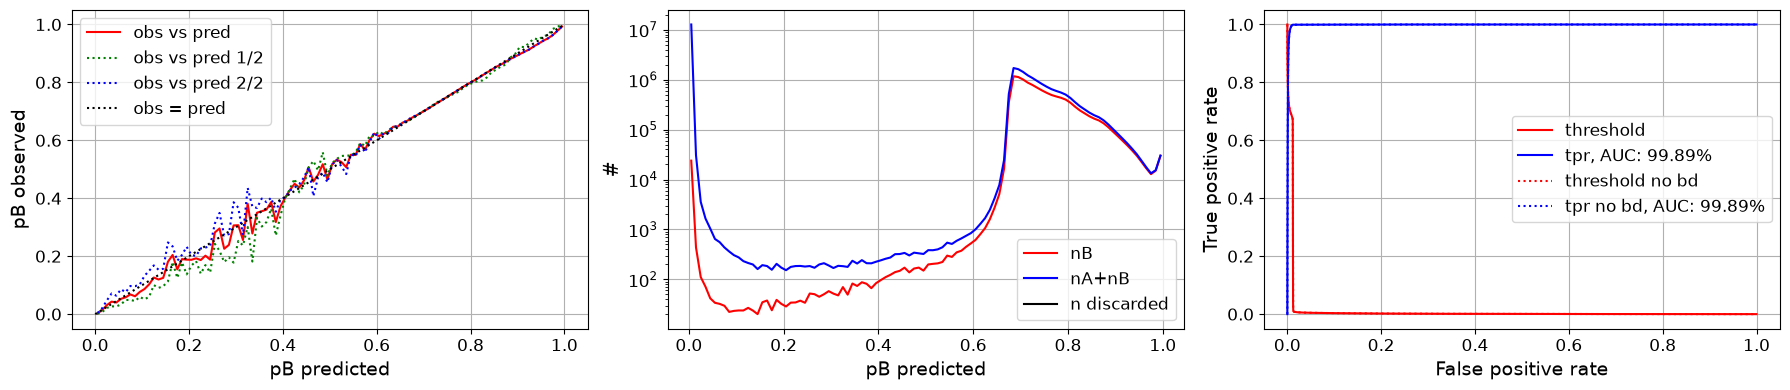

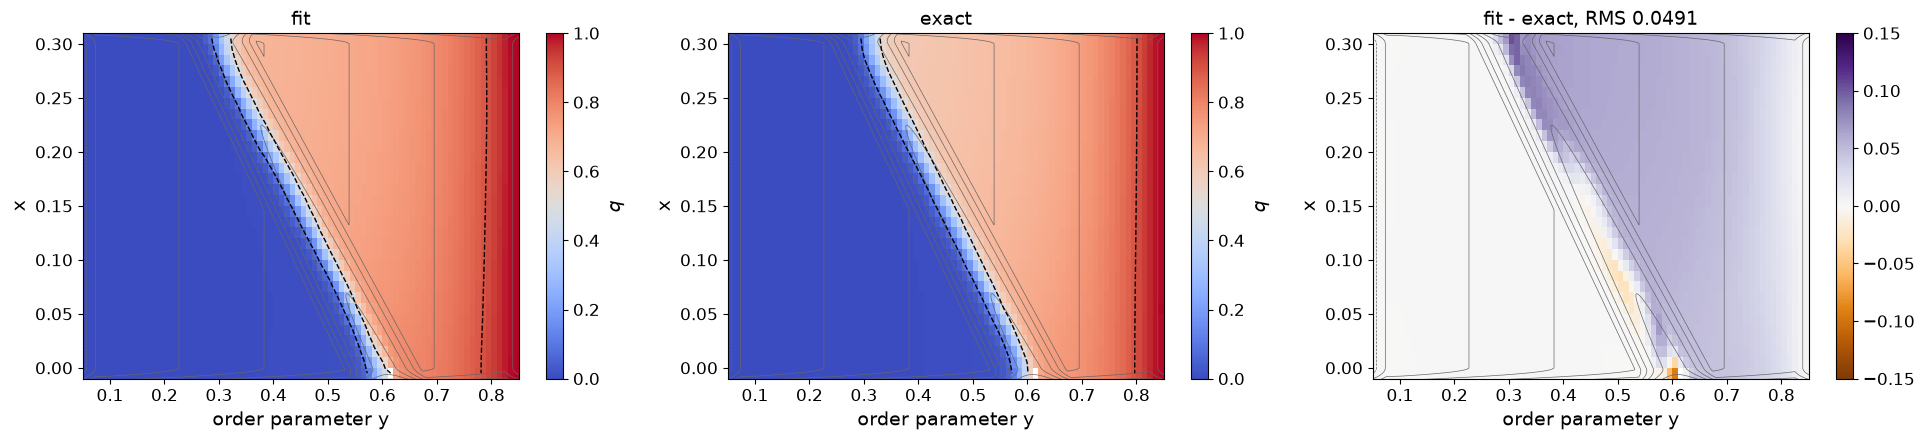

seed 45, 16000 iterations (main: envelope 0.01, gamma 0.0) | fit/shooting at plateau points: 0.699/0.639 0.729/0.664 0.747/0.698 0.794/0.747
seed 45: | fit/shooting at plateau points: 0.699/0.639 0.729/0.664 0.747/0.698 0.794/0.747


In [9]:
import seed_runs

CONTINUE = False                    # start every seed from the saved fit
ADD_DIAG = False                   # add y + x as a CV
MAX_ITER = 15000                   # iterations per seed (after the warm-up)
SEEDS = [45]
CHUNK = 5000                       # iterations between shown and saved plots
ENVELOPE = 0.01                    # envelope_scale (library default, as in the original fit)
GAMMA = 0.                        # regularization strength
WARMUP_ITER = 1000                    # optional warm-up (0 = off)
WARMUP_ENVELOPE = 1000000
WARMUP_GAMMA = GAMMA
WARMUP_CV = None                   # None: random CV; 0: y, 1: x, 2: y + x
PLOTS = ('metrics', 'tis', 'feps', 'obs_pred',)         # add 'feps', 'obs_pred' if GPU memory allows (20.8M frames)
OUT = f'{FIG}/nb_brownian_staple/{"diag" if ADD_DIAG else "yx"}{"_cont" if CONTINUE else ""}'

cvs = [y_pos, x_pos] + ([y_pos + x_pos] if ADD_DIAG else [])
X_gpu = cp.asarray(np.column_stack(cvs))

def make_q():
    q = optimalrcs.CommittorNE(
        boundary0=boundary0,           # state A
        boundary1=boundary1,           # state B
        i_traj=i_traj,                 # path
        t_traj=t_traj,                 # MD step
        path_weights=path_weights,
        group_traj=group_traj,
        seed_r=r_saved if (CONTINUE and r_saved is not None) else None,
    )
    q.set_fixed_traj_length_trap(boundary0 | boundary1, 2 ** 16)
    return q

# progress: the fit at the four plateau points checked by shooting with the toytis engine
SHOOT = [((0.50, 0.25), 0.639), ((0.55, 0.10), 0.664), ((0.62, 0.15), 0.698), ((0.70, 0.15), 0.747)]
free_np = ~(boundary0 | boundary1)
NEAR = [cp.asarray(np.flatnonzero(free_np & ((y_pos - y0) ** 2 + (x_pos - x0) ** 2 < 0.01 ** 2))) for (y0, x0), _ in SHOOT]
def report(q):
    return '| fit/shooting at plateau points: ' + ' '.join(
        f'{float(q.r_traj[idx].mean()):.3f}/{qs:.3f}' for idx, (_, qs) in zip(NEAR, SHOOT))

# after every chunk: q on (y, x) next to the exact committor and fit - exact, on the effective potential
# (the maps of section 4; ref, q_exact, V and lev are used there as well)
ref = np.load(f'{FIG}/z_brownian/committor_reference_h0.001.npz')
f_ref = RegularGridInterpolator((ref['y'], ref['x']), ref['q'], bounds_error=False, fill_value=None)
q_exact = np.clip(f_ref(np.c_[y_pos, x_pos]), 0, 1)
V = ref['V_eff']; inside = (ref['y'] >= -0.01) & (ref['y'] <= 0.91)
lev = np.linspace(np.percentile(V[inside], 1), np.percentile(V[inside], 92), 14)
q_map = seed_runs.committor_map(
    [seed_runs.plane(y_pos, np.linspace(0.05, 0.85, 81), 'order parameter y', x_pos, np.linspace(-0.01, 0.31, 33), 'x',
                     contours=(ref['y'][inside], ref['x'], V[inside], lev))],
    mask=free_np, q_ref=q_exact)

results, q = seed_runs.run_seeds(
    optimalrcs, make_q,
    comp_y=lambda: X_gpu[:, np.random.randint(X_gpu.shape[1])],
    fit_kw=dict(ny=6, print_step=500, min_delta_x=1e-6, lazy_basis=True, save_min_metric='max_z_zq_stopped',
                metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed')),
    seeds=SEEDS, max_iter=MAX_ITER, chunk=CHUNK, out_dir=OUT, envelope=ENVELOPE, gamma=GAMMA,
    warmup_iter=WARMUP_ITER, warmup_envelope=WARMUP_ENVELOPE, warmup_gamma=WARMUP_GAMMA,
    warmup_comp_y=None if WARMUP_CV is None else (lambda: X_gpu[:, WARMUP_CV]),
    plots=PLOTS, plot_options=dict(metrics=['delta_r2', 'max_z_zq_stopped', 'delta_x']),
    extra_plot={'q_y_x': q_map},
    report=report,
)

32187 pieces: 23588 end at a turn, 8599 in A or B; longest 5463 frames, A/B trap 65536
#=500, dr2=213.126, zqs_z=6.94453, sdzqs=6.13756, |dx|=0.373545, time=37.7046
#=1000, dr2=210.113, zqs_z=6.46313, sdzqs=5.88138, |dx|=0.00111986, time=75.206
#=1500, dr2=208.785, zqs_z=6.17648, sdzqs=5.83341, |dx|=0.000499739, time=112.713
#=2000, dr2=207.909, zqs_z=6.01563, sdzqs=5.86617, |dx|=0.000368868, time=150.214
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_zpot/brownian_g10/staple/notebook/yx_stopped_drop0.13/seed580/it2000 ---


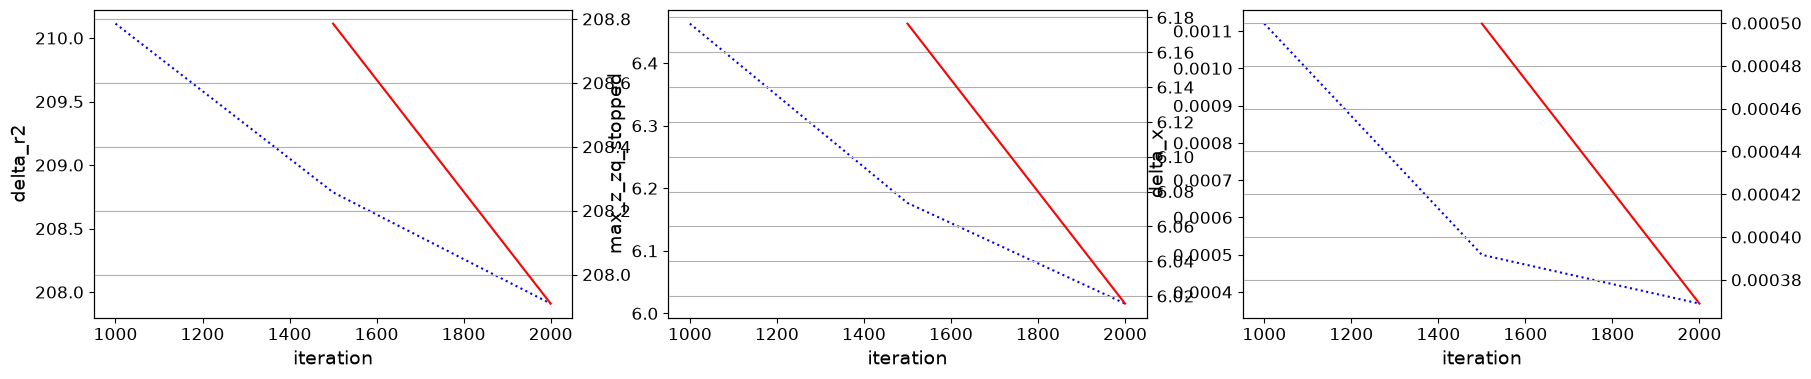

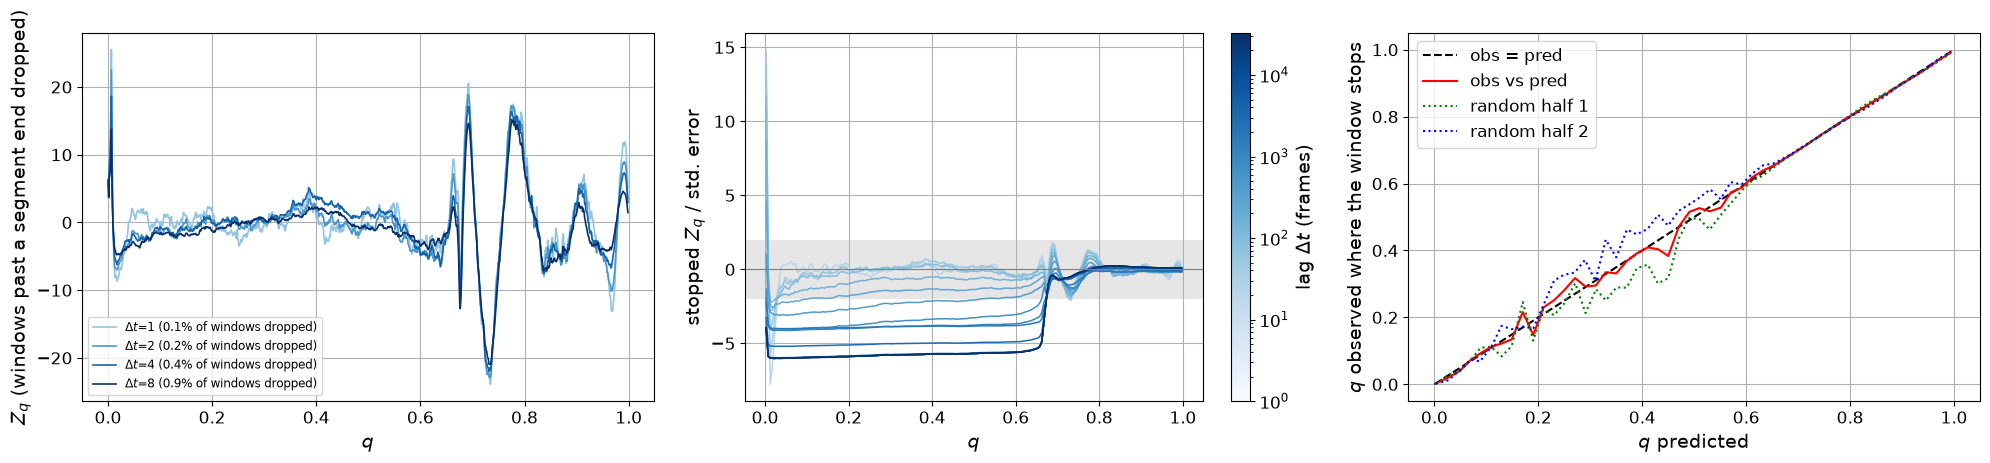

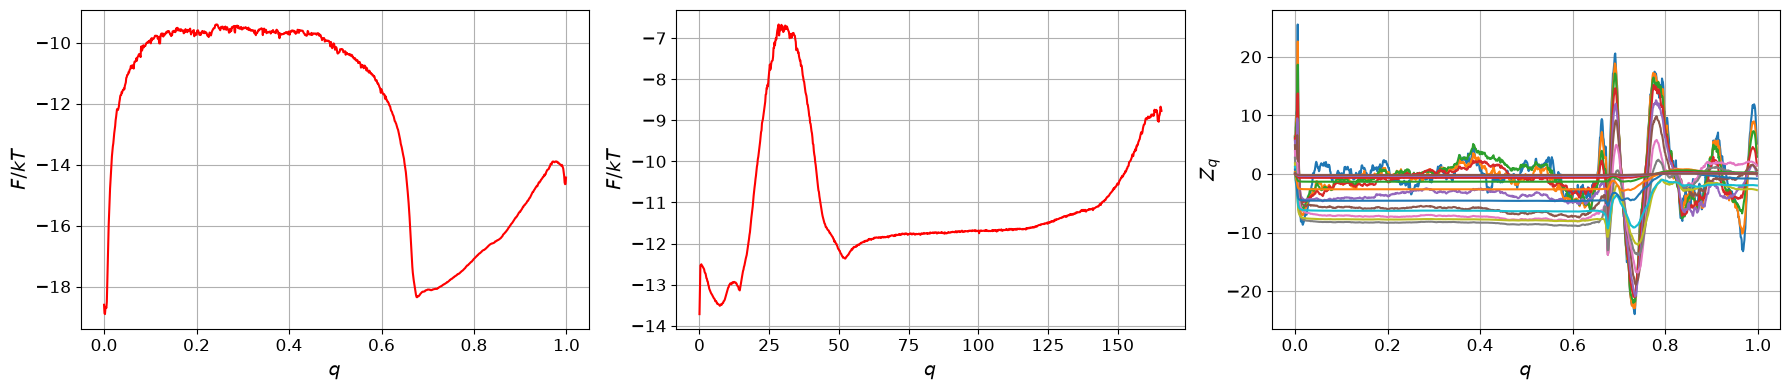

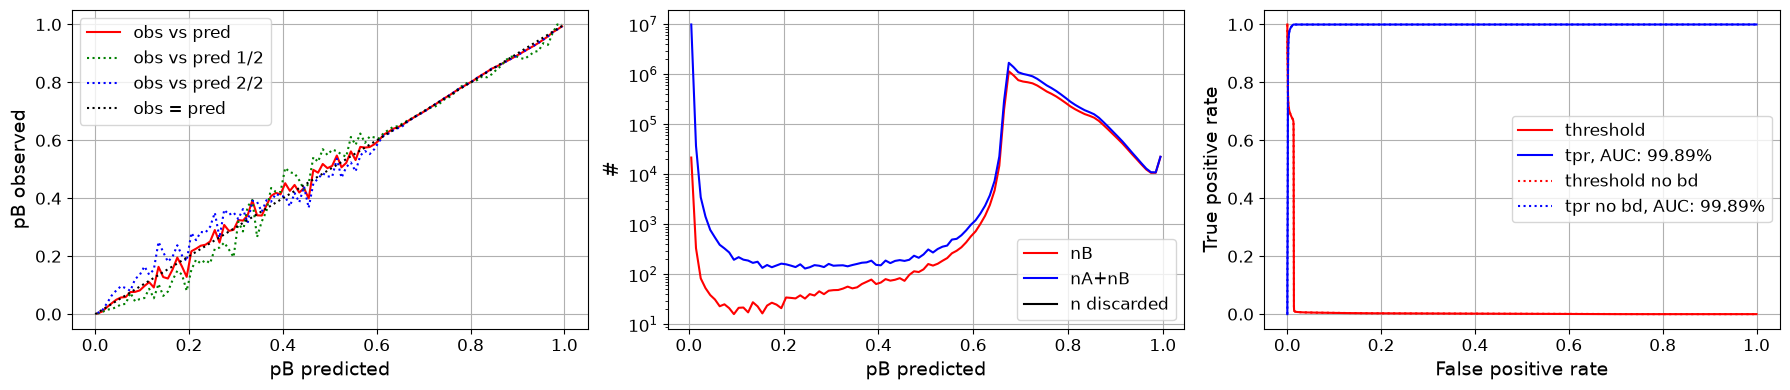

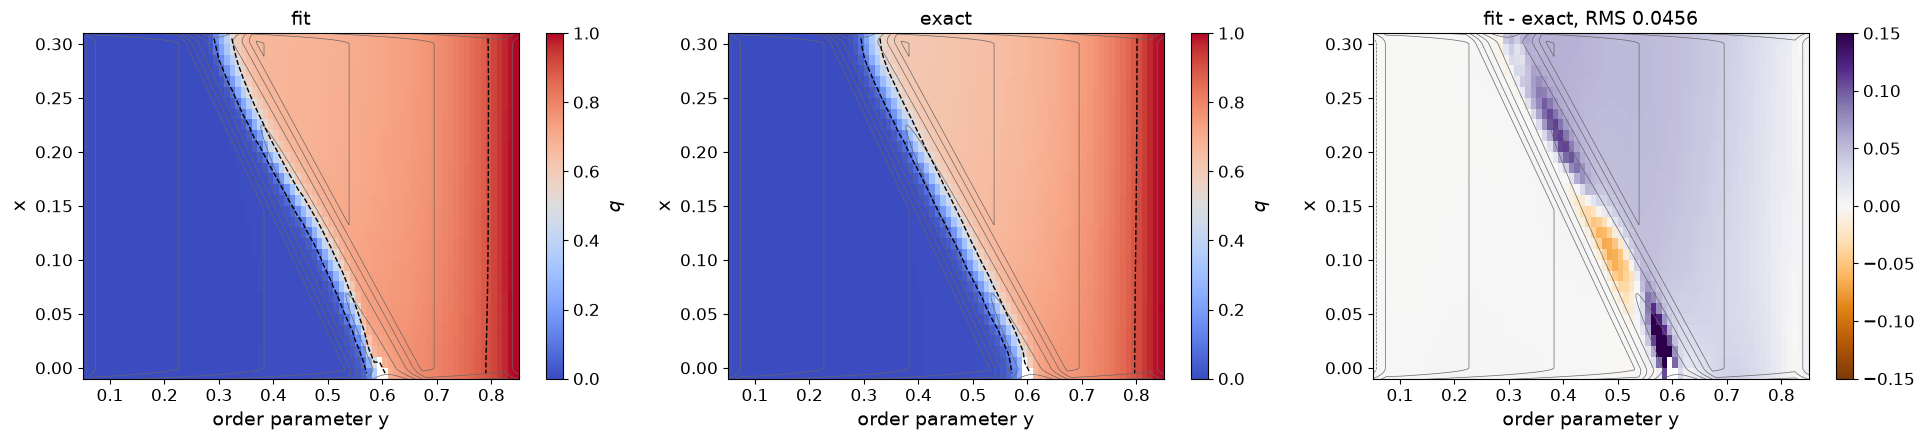

seed 580, 2000 iterations (warm-up: envelope 1000000, gamma 0.0) | fit/shooting at plateau points: 0.689/0.639 0.721/0.664 0.736/0.698 0.781/0.747
#=2500, dr2=199.002, zqs_z=4.58946, sdzqs=2.32425, |dx|=0.00396234, time=37.4312
#=3000, dr2=198.224, zqs_z=4.64608, sdzqs=2.30858, |dx|=0.000553267, time=74.9244
#=3500, dr2=197.996, zqs_z=4.58948, sdzqs=2.24656, |dx|=0.000118655, time=112.415
#=4000, dr2=197.796, zqs_z=4.66387, sdzqs=2.26571, |dx|=0.000130737, time=149.914
#=4500, dr2=197.715, zqs_z=4.69649, sdzqs=2.24922, |dx|=5.7483e-05, time=187.416
#=5000, dr2=197.674, zqs_z=4.70222, sdzqs=2.30842, |dx|=5.50254e-05, time=224.924
#=5500, dr2=197.508, zqs_z=4.74605, sdzqs=2.22524, |dx|=0.000155289, time=262.419
#=6000, dr2=197.51, zqs_z=4.66999, sdzqs=2.21253, |dx|=7.57535e-05, time=299.935
#=6500, dr2=197.479, zqs_z=4.76664, sdzqs=2.21932, |dx|=5.524e-05, time=337.432

Training interrupted at iteration 6580; keeping the RC of the last completed update.
--- /home/staff7/fbsskr/Notebooks/

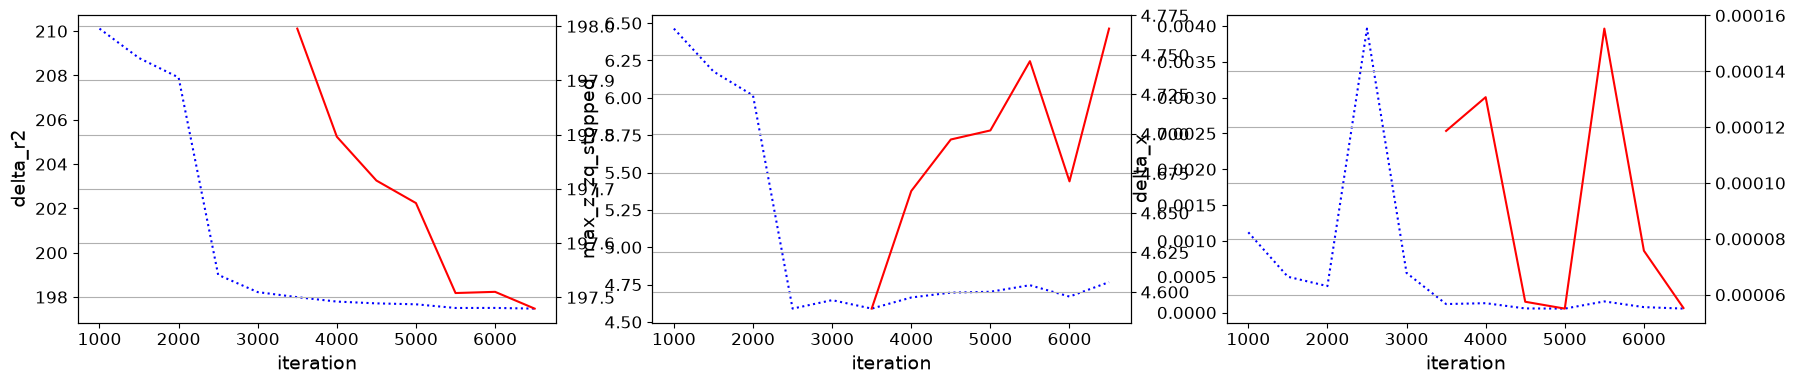

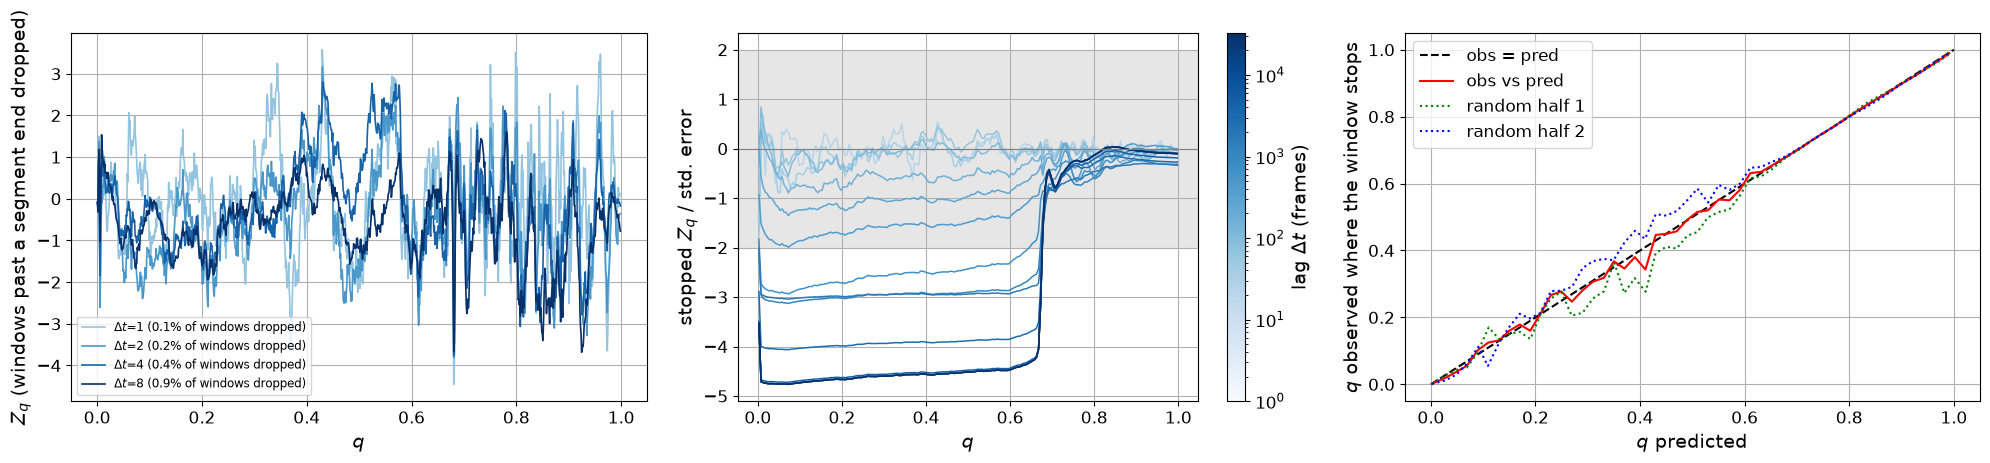

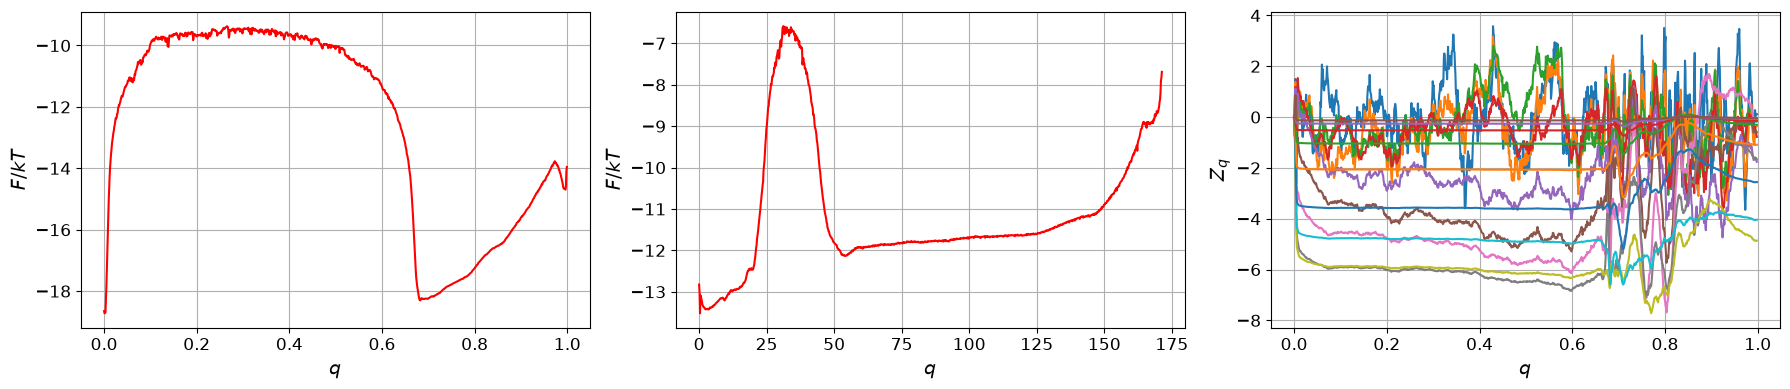

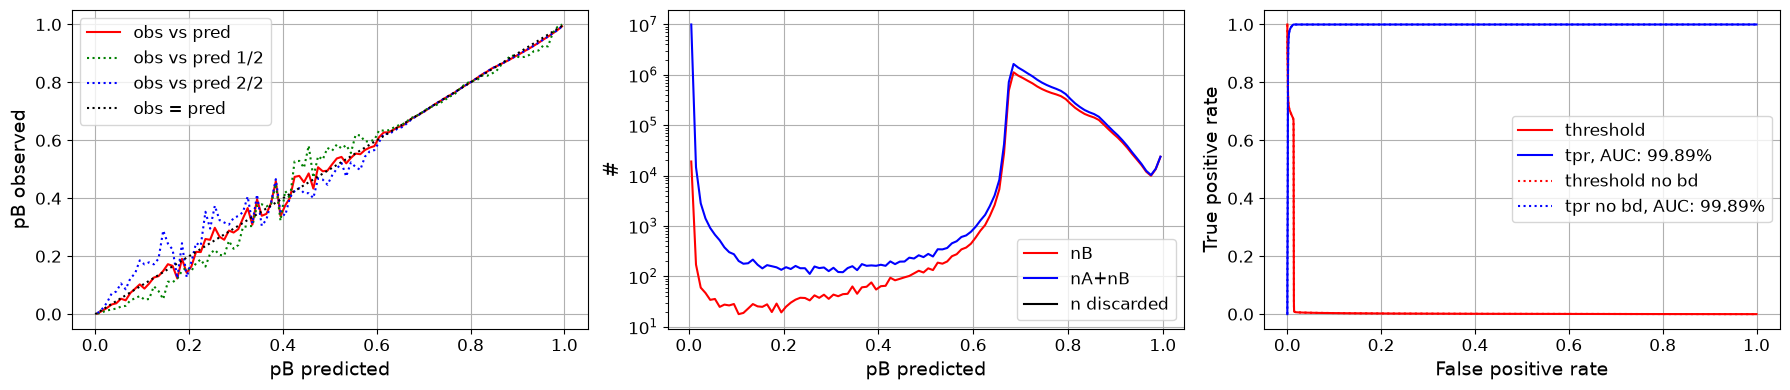

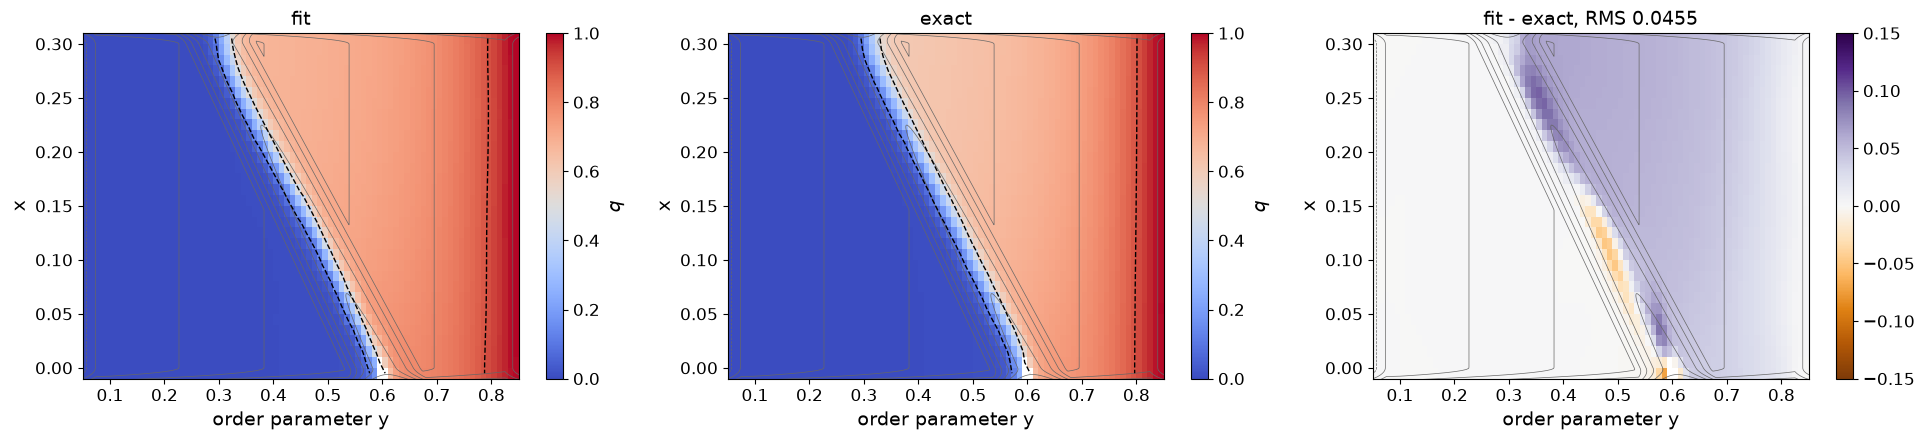

seed 580, 7000 iterations (main: envelope 0.01, gamma 0.0) | fit/shooting at plateau points: 0.696/0.639 0.723/0.664 0.742/0.698 0.787/0.747


OutOfMemoryError: Out of memory allocating 185,952,768 bytes (allocated so far: 15,949,285,888 bytes).

In [23]:
import seed_runs

CONTINUE = False                    # start every seed from the saved fit
ADD_DIAG = False                   # add y + x as a CV
MAX_ITER = 15000                   # iterations per seed (after the warm-up)
SEEDS = [580]
CHUNK = 5000                       # iterations between shown and saved plots
ENVELOPE = 0.01                    # envelope_scale (library default, as in the original fit)
GAMMA = 0.                        # regularization strength
WARMUP_ITER = 2000                    # optional warm-up (0 = off)
WARMUP_ENVELOPE = 1000000
WARMUP_GAMMA = GAMMA
WARMUP_CV = None                   # None: random CV; 0: y, 1: x, 2: y + x
PLOTS = ('metrics', 'tis', 'feps', 'obs_pred',)         # add 'feps', 'obs_pred' if GPU memory allows (20.8M frames)
STOPPED_ENDS = True               # Z_q of 'feps' (and the max_sd_zq metric): windows past a piece end that is not in A/B use q there
OUT = f'{FIG}/2d_zpot/brownian_g10/staple/notebook/yx_stopped_drop0.13'

# Stopped Z_q with traps. Every piece ends in A, in B, or at a turn (forward pieces: the path's end; mirrored pieces: its start).
# A/B ends: a fixed trap long enough that no window is dropped at any lag (longest piece + longest Z_q lag).
# Turn ends: set_stopped_traj_end, so a window passing the end uses q at the end, q(min(t + dt, tau)) - q(t).
# The 'feps' Z_q is then the stopped Z_q (not normalised); the 'tis' plot shows the same test divided by its standard error.
piece_end = np.r_[np.flatnonzero(np.diff(i_traj)), len(i_traj) - 1]
stop_end = np.zeros(len(i_traj), bool)
stop_end[piece_end] = ~(boundary0 | boundary1)[piece_end]
TRAP_LEN = max(2 ** 16, int(np.bincount(i_traj).max()) + 2 ** 15 + 1)       # Z_q lags go up to 2^15
print(f'{len(piece_end)} pieces: {stop_end.sum()} end at a turn, {len(piece_end) - stop_end.sum()} in A or B; '
      f'longest {np.bincount(i_traj).max()} frames, A/B trap {TRAP_LEN}')

cvs = [y_pos, x_pos] + ([y_pos + x_pos] if ADD_DIAG else [])
X_gpu = cp.asarray(np.column_stack(cvs))

def make_q():
    q = optimalrcs.CommittorNE(
        boundary0=boundary0,           # state A
        boundary1=boundary1,           # state B
        i_traj=i_traj,                 # path
        t_traj=t_traj,                 # MD step
        path_weights=path_weights,
        group_traj=group_traj,
        seed_r=r_saved if (CONTINUE and r_saved is not None) else None,
    )
    q.set_fixed_traj_length_trap(boundary0 | boundary1, TRAP_LEN)
    if STOPPED_ENDS:
        q.set_stopped_traj_end(stop_end)
    return q

# progress: the fit at the four plateau points checked by shooting with the toytis engine
SHOOT = [((0.50, 0.25), 0.639), ((0.55, 0.10), 0.664), ((0.62, 0.15), 0.698), ((0.70, 0.15), 0.747)]
free_np = ~(boundary0 | boundary1)
NEAR = [cp.asarray(np.flatnonzero(free_np & ((y_pos - y0) ** 2 + (x_pos - x0) ** 2 < 0.01 ** 2))) for (y0, x0), _ in SHOOT]
def report(q):
    return '| fit/shooting at plateau points: ' + ' '.join(
        f'{float(q.r_traj[idx].mean()):.3f}/{qs:.3f}' for idx, (_, qs) in zip(NEAR, SHOOT))

# after every chunk: q on (y, x) next to the exact committor and fit - exact, on the effective potential
# (the maps of section 4; ref, q_exact, V and lev are used there as well)
ref = np.load(f'{FIG}/2d_zpot/brownian_g10/reference_and_analyses/committor_reference_h0.001.npz')
f_ref = RegularGridInterpolator((ref['y'], ref['x']), ref['q'], bounds_error=False, fill_value=None)
q_exact = np.clip(f_ref(np.c_[y_pos, x_pos]), 0, 1)
V = ref['V_eff']; inside = (ref['y'] >= -0.01) & (ref['y'] <= 0.91)
lev = np.linspace(np.percentile(V[inside], 1), np.percentile(V[inside], 92), 14)
q_map = seed_runs.committor_map(
    [seed_runs.plane(y_pos, np.linspace(0.05, 0.85, 81), 'order parameter y', x_pos, np.linspace(-0.01, 0.31, 33), 'x',
                     contours=(ref['y'][inside], ref['x'], V[inside], lev))],
    mask=free_np, q_ref=q_exact)

results, q = seed_runs.run_seeds(
    optimalrcs, make_q,
    comp_y=lambda: X_gpu[:, np.random.randint(X_gpu.shape[1])],
    fit_kw=dict(ny=6, print_step=500, min_delta_x=1e-6, lazy_basis=True, save_min_metric='max_z_zq_stopped',
                metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed')),
    seeds=SEEDS, max_iter=MAX_ITER, chunk=CHUNK, out_dir=OUT, envelope=ENVELOPE, gamma=GAMMA,
    warmup_iter=WARMUP_ITER, warmup_envelope=WARMUP_ENVELOPE, warmup_gamma=WARMUP_GAMMA,
    warmup_comp_y=None if WARMUP_CV is None else (lambda: X_gpu[:, WARMUP_CV]),
    plots=PLOTS, plot_options=dict(metrics=['delta_r2', 'max_z_zq_stopped', 'delta_x']),
    extra_plot={'q_y_x': q_map},
    report=report,
)

## 4. Comparison with the Exact Committor

The exact committor of this dynamics (finite-volume solution of the backward equation, `figures_by_potential/2d_zpot/brownian_g10/reference_and_analyses/committor_reference.py`, for A: y ≤ 0.05, B: y ≥ 0.85, absorption checked every step), confirmed by shooting with the toytis engine at four plateau points (1200 trajectories each). Maps show the mean q per (y, x) bin with at least 20 frames; grey: contours of the effective potential; dashed: q = 0.1, 0.5, 0.9.

In [24]:
r = cp.asnumpy(q.r_traj)          # ref, q_exact, V and lev: loaded in section 3
free = ~(boundary0 | boundary1)

ey, ex = np.linspace(0.05, 0.85, 81), np.linspace(-0.01, 0.31, 33)
cy, cx = (ey[1:] + ey[:-1]) / 2, (ex[1:] + ex[:-1]) / 2
n_bin = np.histogram2d(y_pos[free], x_pos[free], bins=(ey, ex))[0]
def bin_mean(val):
    s = np.histogram2d(y_pos[free], x_pos[free], bins=(ey, ex), weights=val[free])[0]
    return np.where(n_bin >= 20, s / np.maximum(n_bin, 1), np.nan)
Q_fit, Q_ex = bin_mean(r), bin_mean(q_exact)
Q_orig = bin_mean(r_saved) if r_saved is not None else None
trans = (Q_ex > 0.05) & (Q_ex < 0.95)
rms = lambda D: np.sqrt(np.nanmean(D[trans] ** 2))
print(f'per bin, 0.05 < q_exact < 0.95: RMS(fit - exact) {rms(Q_fit - Q_ex):.4f}'
      + (f', original fit {rms(Q_orig - Q_ex):.4f}' if Q_orig is not None else ''))

# plateau points: engine shooting (figures_by_potential/2d_zpot/brownian_g10/reference_and_analyses/shoot_engine.py)
shoot = [((0.50, 0.25), 0.639, 0.014), ((0.55, 0.10), 0.664, 0.014), ((0.62, 0.15), 0.698, 0.013), ((0.70, 0.15), 0.747, 0.013)]
print('point (y, x)   shooting        fit     original fit')
for (y0, x0), qs, se in shoot:
    near = free & ((y_pos - y0) ** 2 + (x_pos - x0) ** 2 < 0.01 ** 2)
    print(f'({y0:.2f}, {x0:.2f})   {qs:.3f} +- {se:.3f}   {r[near].mean():.3f}'
          + (f'    {r_saved[near].mean():.3f}' if r_saved is not None else ''))

panels = [(Q_fit, 'this fit', 'coolwarm', (0, 1)), (Q_ex, 'exact committor', 'coolwarm', (0, 1)),
          (Q_fit - Q_ex, 'this fit - exact', 'PuOr', (-0.15, 0.15))]
if Q_orig is not None:
    panels.append((Q_orig - Q_ex, 'original fit (10000 it.) - exact', 'PuOr', (-0.15, 0.15)))
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for ax, (M, title, cmap, (vmin, vmax)) in zip(axes.ravel(), panels):
    im = ax.imshow(M.T, origin='lower', extent=[ey[0], ey[-1], ex[0], ex[-1]], aspect='auto', cmap=cmap, vmin=vmin, vmax=vmax)
    ax.contour(ref['y'][inside], ref['x'], V[inside].T, levels=lev, colors='0.4', linewidths=0.5)
    if vmin == 0:
        ax.contour(cy, cx, np.nan_to_num(M, nan=0.5).T, levels=[0.1, 0.5, 0.9], colors='k', linewidths=1, linestyles='--')
    ax.set(title=title, xlabel='order parameter y', ylabel='x', xlim=(0.04, 0.86), ylim=(-0.01, 0.31))
    fig.colorbar(im, ax=ax)
for ax in axes.ravel()[len(panels):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

IndexError: boolean index did not match indexed array along axis 0; size of axis is 24924259 but size of corresponding boolean axis is 23252671

## 4b. Fit on New Fixed-Length Trajectories from Random Path Frames

A second, independent data set (the PI's validation): `FT_N_POINTS` random frames of the path data (uniform over the frames outside A and B, or with `FT_START = 'q_bins'` equal numbers in 10 bins of the path-data fit: the path frames crowd near the interfaces and, on the 2D Z, on the plateau), one new trajectory of the run's dynamics from each (overdamped, γ = 10, kT = 0.05, dt = 0.002), `FT_LENGTH` steps long or shorter if it reaches A or B (absorption checked every step, as in the run). NPNEq is fitted on these trajectories with the same CVs and settings as the path data, without weights.

- The new trajectories are plain dynamics: no path selection, no cut at M, no mirrored pieces, no MC weights. A fit on them is unbiased whatever the start distribution, so it tests what the path-data preparation and weights may have introduced.
- The Z potential has no vectorized force in toytis; the cell writes it out term by term and checks it against the potential class before running.
- Compared at the start frames (each is a frame of both data sets): the new fit against the path-data fit and against the exact committor. Also the stopped Z_q test per lag on the new data, and the maps.
- **Limits:** trajectories of length L fix the level of q only through the ones that reach A or B (printed as the absorbed fraction). A region the trajectories do not leave within L (the plateau beyond the ridge) has its level set only by the smoothness of the fit, as for the staple pieces. Make L longer to test levels.
- Cost: `FT_N_POINTS` × L frames (10k × the median piece length ≈ 5.5M frames, a quarter of the path data).

In [1]:
# New data: fixed-length trajectories from random path frames, and an NPNEq fit on them
import time
import types
import seed_runs
import toy2d
sys.path.insert(0, toy2d.TOYTIS)
from potentials.sjoelbak_angle import RectangularGridWithAngledBarrierPotential
from plots import transform_q2qn

FT_N_POINTS = 20_000      # random start frames (uniform over the free frames of the path data)
FT_LENGTH = 300          # steps per trajectory; None: the median piece length
FT_START = ''      # 'uniform': random free frames; 'q_bins': equal numbers in 10 bins of the path-data fit
FT_SEED = 0
FT_MAX_ITER, FT_CHUNK = 20000, 2500              # fit settings, as for the path data:
FT_ENVELOPE, FT_GAMMA, FT_NY = 0.01, 0., 6
FT_WARMUP_ITER, FT_WARMUP_ENVELOPE = 1000, 10000000
DT, KT, GAMMA = 0.002, 0.05, 10.0                # the run's dynamics (overdamped)
pot = RectangularGridWithAngledBarrierPotential(Lx=0.3, angle=45)

def z_force(y, x):
    """Force (F_y, F_x) of the potential on arrays (y, x), term by term as in potential_and_force."""
    p = pot
    fx = cp.where(x < 0, -p.k * x, cp.where(x > p.Lx, -p.k * (x - p.Lx), 0.0))        # walls
    fy = cp.where(y < 0, -p.k * y, cp.where(y > p.Ly, -p.k * (y - p.Ly), 0.0))
    norm = np.sqrt(p.r ** 2 + 1)                                                        # tilted ridge
    D = cp.abs(p.r * x - y + p.b) / norm
    dV_dD = cp.where(D < p.L / 4, -2 * np.pi * p.A / p.L * cp.sin(2 * np.pi * D / p.L), 0.0)
    sgn = cp.sign(y - p.r * x - p.b)
    fx = fx + sgn * dV_dD * p.r / norm
    fy = fy - sgn * dV_dD / norm
    for yc, amp, ell in zip(p.state_y, p.state_A, p.state_L):                          # wells of A and B
        Ds = cp.abs(y - yc)
        fy = fy + cp.where(Ds < ell / 4, amp * 2 * np.pi / ell * cp.sin(2 * np.pi * Ds / ell) * cp.sign(y - yc), 0.0)
    span = p.slope_end_y - p.slope_start_y                                               # slope and gravity
    fy = fy + cp.where((y >= p.slope_start_y) & (y <= p.slope_end_y), -p.slope_strength_y / span, 0.0) - p.gravity
    return fy, fx

check = np.random.default_rng(1).uniform([-0.02, -0.02], [0.92, 0.32], size=(300, 2))
f_vec = np.column_stack([a.get() for a in z_force(cp.asarray(check[:, 0]), cp.asarray(check[:, 1]))])
f_cls = np.array([pot.potential_and_force((pt, np.zeros(2)))[1] for pt in check])
assert np.allclose(f_vec, f_cls, atol=1e-9), 'vectorized force differs from the potential class'

r_path = cp.asnumpy(q.r_traj)                    # the path-data fit (q is reused below)
qn_path = transform_q2qn(q.r_traj,      # numpy; the cupy port's version may take cupy arrays instead
                    i_traj=q.i_traj, t_traj=q.t_traj, w_traj=q.w_traj,
                    dt_sim=DT)  
free_path = ~(boundary0 | boundary1)
def exact_at(y, x):
    return np.clip(f_ref(np.column_stack([y, x])), 0, 1)

# 1. start frames and trajectories (all at once on the GPU; a trajectory stops when it reaches A or B)
rng = np.random.default_rng(FT_SEED)
if FT_START == 'uniform':
    start = np.sort(rng.choice(np.flatnonzero(free_path), size=FT_N_POINTS, replace=False))
else:                                            # the path frames crowd near the interfaces and on plateaus
    #q_bin = np.clip((r_path * 10).astype(int), 0, 9)
    q_bin = np.clip((qn_path*30/max(qn_path)).astype(int), 0, 29)
    start = np.sort(np.concatenate([rng.choice(np.flatnonzero(free_path & (q_bin == k)), replace=False,
                                               size=min(FT_N_POINTS // 30, np.sum(free_path & (q_bin == k))))
                                    for k in range(30)]))
FT_N_POINTS = len(start)
piece_end = np.r_[np.flatnonzero(np.diff(i_traj) != 0), len(i_traj) - 1]
L = FT_LENGTH or int(np.median(np.diff(np.r_[-1, piece_end])))
y, x = cp.asarray(y_pos[start]), cp.asarray(x_pos[start])
frames_y, frames_x = cp.zeros((L + 1, FT_N_POINTS)), cp.zeros((L + 1, FT_N_POINTS))   # [step, trajectory]
frames_y[0], frames_x[0] = y, x
last = cp.full(FT_N_POINTS, L)                   # last frame of each trajectory
running = cp.ones(FT_N_POINTS, bool)
sigma = np.sqrt(2 * KT * DT / GAMMA)
cp.random.seed(FT_SEED)
t0 = time.time()
for step in range(1, L + 1):
    fy, fx = z_force(y, x)
    y = y + DT / GAMMA * fy + sigma * cp.random.standard_normal(FT_N_POINTS)
    x = x + DT / GAMMA * fx + sigma * cp.random.standard_normal(FT_N_POINTS)
    frames_y[step], frames_x[step] = y, x
    hit = running & ((y <= lambda_a) | (y >= lambda_b))
    last = cp.where(hit, step, last)
    running &= ~hit
print(f'{FT_N_POINTS} trajectories of up to {L} steps in {time.time() - t0:.0f} s; '
      f'{float(1 - running.mean()):.0%} reached A or B')

# 2. flatten to the fit's format: one segment per trajectory, frames 0 .. last
last = cp.asnumpy(last)
keep = (np.arange(L + 1)[:, None] <= last[None, :]).T                 # [trajectory, step]
ft_y, ft_x = cp.asnumpy(frames_y).T[keep], cp.asnumpy(frames_x).T[keep]
del frames_y, frames_x
ft_i = np.repeat(np.arange(FT_N_POINTS), last + 1)
ft_t = np.concatenate([np.arange(n + 1) for n in last]).astype(float)
ft_first = np.r_[0, np.cumsum(last + 1)[:-1]]                         # index of each start frame
ft_A, ft_B = ft_y <= lambda_a, ft_y >= lambda_b
ft_b = ft_A | ft_B
ft_free = ~ft_b
ft_q_exact = exact_at(ft_y, ft_x)
ft_q_exact[ft_A], ft_q_exact[ft_B] = 0.0, 1.0
print(f'{len(ft_t):,} frames; {ft_A.sum()} in A, {ft_B.sum()} in B')

# 3. NPNEq fit on the new trajectories: same CVs and settings, no weights
ft_X_cv = cp.asarray(np.column_stack([ft_y, ft_x]))
def make_q_ft():
    q_new = optimalrcs.CommittorNE(boundary0=ft_A, boundary1=ft_B, i_traj=ft_i, t_traj=ft_t)
    #q_new.set_fixed_traj_length_trap(ft_b, 2 ** 16)
    return q_new
ey, ex = np.linspace(0.05, 0.85, 81), np.linspace(-0.01, 0.31, 33)
ft_plane = seed_runs.plane(ft_y, ey, 'order parameter y', ft_x, ex, 'x')
ft_results, q_ft = seed_runs.run_seeds(
    optimalrcs, make_q_ft,
    comp_y=lambda: ft_X_cv[:, np.random.randint(ft_X_cv.shape[1])],
    fit_kw=dict(ny=FT_NY, print_step=min(500, FT_CHUNK, FT_WARMUP_ITER or FT_CHUNK), min_delta_x=1e-6, lazy_basis=True, save_min_metric='max_z_zq_stopped',
                metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed')),
    seeds=[FT_SEED], max_iter=FT_MAX_ITER, chunk=FT_CHUNK,
    out_dir=f'{FIG}/nb_brownian_staple/newtraj_n{FT_N_POINTS}_L{L}',
    envelope=FT_ENVELOPE, gamma=FT_GAMMA,
    warmup_iter=FT_WARMUP_ITER, warmup_envelope=FT_WARMUP_ENVELOPE, warmup_gamma=FT_GAMMA,
    plots=('metrics', 'tis', 'feps'), plot_options=dict(metrics=['delta_r2', 'max_z_zq_stopped', 'delta_x']),
    extra_plot={'q_map': seed_runs.committor_map([ft_plane], mask=ft_free, q_ref=ft_q_exact)},
)
r_ft = cp.asnumpy(q_ft.r_traj)
del ft_X_cv, q_ft
cp.get_default_memory_pool().free_all_blocks()

# 4. comparison at the start frames, and the stopped Z_q test on the new data
LAGS = (1, 4, 16, 64, 256, 1024)
z_ft = toy2d.z_per_lag(r_ft, ft_b, ft_i, None, LAGS)
print('new data, new fit: worst |stopped z| at lags', LAGS, ':', ' '.join(f'{z:.1f}' for z in z_ft))
at_start = {'new-trajectory fit': r_ft[ft_first], 'path-data fit': qn_path[start], 'exact': exact_at(y_pos[start], x_pos[start])}
#at_start = {'new-trajectory fit': r_ft[ft_first], 'path-data fit': r_path[start], 'exact': exact_at(y_pos[start], x_pos[start])}
names = list(at_start)
for i, a in enumerate(names):
    for c in names[i + 1:]:
        d = at_start[a] - at_start[c]
        print(f'at the {FT_N_POINTS} start frames: {a} - {c}: mean {d.mean():+.4f}, RMS {np.sqrt(np.mean(d ** 2)):.4f}')
q_bins = np.linspace(0, 1, 21)
q_mid = (q_bins[1:] + q_bins[:-1]) / 2
k = np.clip(np.digitize(at_start['exact'], q_bins) - 1, 0, len(q_mid) - 1)
cnt = np.bincount(k, minlength=len(q_mid))
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 4.8))
ax1.plot(at_start['path-data fit'], at_start['new-trajectory fit'], '.', ms=2, alpha=0.4)
ax1.plot([0, 1], [0, 1], 'k--')
ax1.set(xlabel='path-data fit', ylabel='new-trajectory fit', title='q at the start frames')
for name in ('new-trajectory fit', 'path-data fit'):
    d = at_start[name] - at_start['exact']
    mean = np.bincount(k, weights=d, minlength=len(q_mid)) / np.maximum(cnt, 1)
    sd = np.sqrt(np.maximum(np.bincount(k, weights=d ** 2, minlength=len(q_mid)) / np.maximum(cnt, 1) - mean ** 2, 0))
    ok = cnt >= 10
    ax2.errorbar(q_mid[ok], mean[ok], yerr=sd[ok] / np.sqrt(cnt[ok]), fmt='o-', ms=3, capsize=2, label=f'{name} $-$ exact')
ax2.axhline(0, color='k', lw=0.8)
ax2.set(xlabel='exact at the start frame', ylabel='mean difference (± s.e. over the frames)', title='difference per bin')
ax2.legend()
ax2.grid(alpha=0.3)
ax3.plot(LAGS, z_ft, 'o-')
ax3.axhline(2, color='k', ls=':')
ax3.set(xscale='log', xlabel='lag (frames)', ylabel='worst |stopped $Z_q$ / s.e.|', title='stopped Z_q test of the new fit on the new data')
ax3.grid(alpha=0.3)
fig.suptitle(f'{FT_N_POINTS} new trajectories of up to {L} steps from random path frames')
fig.tight_layout()
fig.savefig(f'{FIG}/nb_brownian_staple/newtraj_comparison_n{FT_N_POINTS}_L{L}_notrap.png', dpi=110, bbox_inches='tight')
plt.show()
fig = seed_runs.committor_map([ft_plane], mask=ft_free, q_ref=ft_q_exact)(types.SimpleNamespace(r_traj=cp.asarray(r_ft)))
fig.savefig(f'{FIG}/nb_brownian_staple/newtraj_map_n{FT_N_POINTS}_L{L}_notrap.png', dpi=110, bbox_inches='tight')
plt.show()

NameError: name 'sys' is not defined

## 5. Save Results

Saves the committor with the frames, in the same format as the original fit's `committor.npz`, so a later run can continue from it (set `FIT_NPZ` to the new file).

In [ ]:
OUT_NPZ = f'{FIG}/istarz_br_g10/committor_long_noweights_{DATA_TAG}{"_diag" if ADD_DIAG else ""}.npz'
np.savez(OUT_NPZ, r=r, lam=lam, X_all=X_all, i_traj=i_traj, t_traj=t_traj, path_weights=path_weights,
         boundary0=boundary0, boundary1=boundary1)
print(f'saved {OUT_NPZ}')